# Patient's Sickness Prediction: Detecting Cardiovascular Disease from a Routine Medical Examination

**Hadi Ghazi**, Lebanese University

*Project topic 2: Patient's Sickness Prediction, using the `cardio` dataset.*

## 1. Introduction

Cardiovascular diseases (CVDs) kill an estimated 17.9 million people every year, more than any other
cause [1]. Many of these deaths could be delayed if patients at risk were identified early. Doctors find
this hard to do reliably by hand: no single measurement settles the question, and the risk builds up
from many small factors.

**Objective.** Build a model that uses the values collected at a routine medical examination (age,
sex, height, weight, blood pressure, cholesterol, glucose, and three lifestyle questions) to tell
whether a patient has a cardiovascular disease. Then evaluate how well it does this. The final model
is delivered with a function that gives a verdict and a risk for a new patient (Section 10).

The dataset [2] has 70,000 patients, which is large for medical tabular data, but it is not clean. Some
recorded blood pressures are impossible, such as −150 or 16,020 mmHg. The signal is also modest:
careful studies of this dataset report about 73% accuracy [5]. Other published papers report 88% [6]
and even 94.5% [7] on the same data, which is hard to reconcile with that. Three questions therefore guide the evaluation, so
that the final model comes with an honest account of what it can do:

- **Q1. How much does machine learning improve on what a doctor already has?** The models are
  compared with two clinical baselines. The first is a blood-pressure threshold from the ACC/AHA 2017
  guideline [3]: systolic pressure of at least 130 mmHg, stage 1 hypertension. The second is the
  Framingham office-based risk score [4], which uses age, sex, BMI, blood pressure, smoking and
  diabetes.
- **Q2. How much do data-handling choices change the measured performance?** This covers the
  cleaning strategy, and the common mistakes that let information from the test set leak into
  training. Reproducing those mistakes shows how accuracies far above 73% can be produced.
- **Q3. Can the final model's predictions be trusted and explained?** This covers which factors drive
  the predictions, whether a simple points score can match the best model, whether predicted risks
  match observed frequencies, and whether errors are evenly spread across sexes and age groups.

**Structure.** Section 2 fixes the evaluation protocol before any model is trained. Section 3
describes the data, Section 4 cleans it, Section 5 explores it, and Section 6 derives features.
Section 7 trains and compares the models (Q1), Section 8 evaluates the chosen model on the test set
and explains it, and Section 9 runs the reliability checks (Q2, Q3). Section 10 shows the model in
use, and Section 11 concludes, with the study's limitations.

All the project's code is in this notebook, each part placed where it is first needed. The first
cell holds the libraries, the file locations and the constants used throughout. The notebook finds
its folder by looking for `data/cardio.csv`.

In [1]:
import math
import os
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "cardio.csv").exists())
DATA = ROOT / "data" / "cardio.csv"
OUTPUTS = ROOT / "outputs"
SEED = 42
TEST_SIZE = 0.2
TARGET = "cardio"

# Plausibility bounds for adults at a routine examination. They are deliberately wide: they remove
# values that cannot be measurements of a living adult, not patients who are merely unusual.
BOUNDS = {
    "ap_hi": (70, 250),   # systolic blood pressure, mmHg
    "ap_lo": (40, 150),   # diastolic blood pressure, mmHg
    "height": (120, 220),  # cm
    "weight": (30, 200),   # kg
}
BMI_BOUNDS = (12, 70)

STRATEGIES = ("raw", "drop", "repair")
STRATEGY_TEXT = {
    "raw": "no cleaning: exact duplicates removed, every value kept as recorded",
    "drop": "remove every record with an implausible value",
    "repair": "fix blood pressures with a recognisable entry error, then remove what is still implausible",
}

# Features as the models will see them, after prepare() and add_features().
BASE_FEATURES = ["age_years", "male", "height", "weight", "ap_hi", "ap_lo",
                 "cholesterol", "gluc", "smoke", "alco", "active"]
DERIVED_FEATURES = ["bmi", "pulse_pressure", "mean_arterial_pressure", "bp_stage"]
FEATURES = BASE_FEATURES + DERIVED_FEATURES

# ACC/AHA 2017 blood-pressure categories (0 normal, 1 elevated, 2 stage 1, 3 stage 2)
BP_STAGE_NAMES = ["normal", "elevated", "stage 1", "stage 2"]

In [2]:
import matplotlib.pyplot as plt

FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

# One look for every figure: thin marks, recessive axes, a fixed colour for each class
NO_CVD, CVD, FLAG, INK, MUTED = "#2a78d6", "#eb6834", "#e34948", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5, "legend.frameon": False,
})

## 2. Evaluation protocol

The protocol is fixed before modelling, so that no result can steer the choices behind it.

1. **Exact duplicates are removed first.** There are 24 records that repeat another record in every
   column except `id`. If a pair were split between training and test data, the model would be
   tested on a patient it had already seen.
2. **One stratified train/test split.** 80% of patients go to training and 20% to test (seed 42).
   The split is drawn once, by patient id, from the deduplicated raw data. Every later comparison
   uses the same ids. Exploratory analysis (Section 5) and every modelling decision use the training
   patients only.
3. **Cleaning learns nothing from the data.** It applies fixed per-record rules, so it cannot leak
   test information into training. Anything that *is* learned (scaling, model parameters, thresholds)
   is fitted on training data only, inside cross-validation folds during model selection.
4. **Model selection.** Models are tuned and compared with 5-fold stratified cross-validation on the
   training set. The test set is scored once, for the final comparison, and never used to choose
   anything.
5. **Common test set.** When cleaning strategies are compared, all of them are scored on the same
   test patients: those whose records pass every plausibility check. A deployed system would reject
   an impossible input at entry rather than predict from it. How each strategy handles the remaining
   records is reported separately.
6. **Metrics.** The primary metric is ROC AUC: how well the model ranks diseased patients above
   healthy ones, independent of any threshold. Accuracy, sensitivity (the share of diseased patients
   detected) and specificity (the share of healthy patients cleared) are reported at the 0.5
   threshold and at a screening threshold chosen on training data. The Brier score and calibration
   curves measure how far predicted risks can be trusted. Every test metric gets a 95% bootstrap
   confidence interval, because with about 14,000 test patients a difference of one point in
   accuracy can be noise.
7. **The leakage experiments (Q2) are kept separate.** They reproduce mistakes on purpose. They are
   labelled as such and never feed into the choice of the final model.

## 3. The data

The dataset is read exactly as distributed. Exact duplicate records, identical in every column but
`id`, are removed before anything else (Section 2).

In [3]:
def load(path: Path | str = DATA) -> pd.DataFrame:
    """The dataset exactly as distributed."""
    return pd.read_csv(path)


def deduplicate(df: pd.DataFrame) -> pd.DataFrame:
    """Drop exact duplicate records (identical in every column except id), keeping the first.

    A duplicate pair split across train and test would let a model be tested on a patient it was
    trained on. Records with identical features but different diagnoses are kept: they are
    contradictory, not duplicated, and removing them would make the task look easier than it is.
    """
    return df[~df.drop(columns="id").duplicated()].reset_index(drop=True)

In [4]:
raw = load()
print(f"{len(raw):,} records, {raw.shape[1]} columns")
raw.head()

70,000 records, 13 columns


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


| Column | Meaning | Type |
|---|---|---|
| `age` | age in days | integer, objective |
| `gender` | 1 or 2 (a code, see below) | categorical, objective |
| `height`, `weight` | cm, kg | numeric, objective |
| `ap_hi`, `ap_lo` | systolic and diastolic blood pressure, mmHg | numeric, measured at the exam |
| `cholesterol`, `gluc` | 1 normal, 2 above normal, 3 well above normal | ordinal, lab result |
| `smoke`, `alco`, `active` | smoking, alcohol intake, physical activity | binary, **self-reported** |
| `cardio` | presence of cardiovascular disease | binary target |

In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.420,28851.302,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.866,2467.252,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.350,0.477,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359,8.210,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.206,14.396,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817,154.011,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630,188.473,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.367,0.680,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226,0.572,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088,0.283,0.0,0.00,0.0,0.00,1.0


In [6]:
print("Target balance:", raw["cardio"].value_counts(normalize=True).round(3).to_dict())
print("Missing values:", int(raw.isna().sum().sum()))
print("Mean height by gender code:", raw.groupby("gender")["height"].mean().round(1).to_dict())

Target balance: {0: 0.5, 1: 0.5}
Missing values: 0
Mean height by gender code: {1: 161.4, 2: 169.9}


The classes are almost perfectly balanced and no cell is empty, so the problems hide in the values
themselves. The documentation never says which gender code is which. Code 2 is about 8.5 cm taller
on average, the usual adult sex difference, so code 2 is taken as male. Age is in days and is
converted to years. Ages run from 30 to 65, so this is a middle-aged adult population.

## 4. Data quality

### 4.1 Plausibility audit

Each record is checked against deliberately wide physiological bounds. They are meant to catch values
that cannot be a measurement of a living adult, not patients who are merely unusual:

In [7]:
pd.DataFrame(
    [(col, lo, hi) for col, (lo, hi) in BOUNDS.items()] + [("BMI", *BMI_BOUNDS)],
    columns=["quantity", "lower bound", "upper bound"],
).set_index("quantity")

,lower bound,upper bound
quantity,,
ap_hi,70,250
ap_lo,40,150
height,120,220
weight,30,200
BMI,12,70


The code below defines the plausibility checks, the repair rules of Section 4.2 and the three
cleaning strategies. Nothing in it is learned from the data: every rule looks at one record at a time.

In [8]:
def bmi(df: pd.DataFrame) -> pd.Series:
    return df["weight"] / (df["height"] / 100) ** 2


def audit(df: pd.DataFrame) -> pd.DataFrame:
    """One boolean column per plausibility check, True where the record fails it."""
    checks = {f"{col} out of range": ~df[col].between(lo, hi) for col, (lo, hi) in BOUNDS.items()}
    checks["diastolic >= systolic"] = df["ap_lo"] >= df["ap_hi"]
    checks["BMI out of range"] = ~bmi(df).between(*BMI_BOUNDS)
    return pd.DataFrame(checks, index=df.index)


def repair_pressure(value: float, lo: float, hi: float) -> tuple[float, str | None]:
    """The reading a recorded blood pressure most plausibly was, and the rule that recovered it.

    Returns (nan, None) when no rule gives a plausible value. Rules, in order:
      sign          a negative reading is the same reading with a stray minus (-120 -> 120)
      cmHg          recorded in cmHg instead of mmHg (12 -> 120), only if that lands in range
      extra digits  trailing digits typed by mistake (1000 -> 100, 14020 -> 140, 906 -> 90)
    """
    if pd.isna(value):
        return math.nan, None
    rule = None
    if value < 0:
        value, rule = -value, "sign"
    if lo <= value <= hi:
        return value, rule
    if 0 < value < lo:
        return (value * 10, "cmHg") if lo <= value * 10 <= hi else (math.nan, None)
    if value > hi:
        value = int(value)
        while value > hi:
            value //= 10
        return (value, "extra digits") if value >= lo else (math.nan, None)
    return math.nan, None  # zero


def repair(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Blood pressures with a recognisable entry error, corrected; plus a log of every change.

    Height and weight are not repaired: their errors show no pattern that identifies the true value.
    A value no rule can recover becomes NaN, so the record fails audit() and is dropped afterwards.
    """
    out = df.copy()
    out[["ap_hi", "ap_lo"]] = out[["ap_hi", "ap_lo"]].astype(float)  # room for NaN
    log = []
    for col in ("ap_hi", "ap_lo"):
        lo, hi = BOUNDS[col]
        bad = ~out[col].between(lo, hi)
        for idx in out.index[bad]:
            before = out.at[idx, col]
            after, rule = repair_pressure(before, lo, hi)
            out.at[idx, col] = after
            log.append({"id": out.at[idx, "id"], "field": col, "before": f"{before:g}",
                        "after": "" if math.isnan(after) else f"{after:g}",
                        "rule": rule or "unrecoverable"})
    # systolic and diastolic typed into each other's field
    swapped = (out["ap_lo"] > out["ap_hi"]) & out["ap_hi"].between(*BOUNDS["ap_lo"]) \
        & out["ap_lo"].between(*BOUNDS["ap_hi"])
    for idx in out.index[swapped]:
        hi_, lo_ = out.at[idx, "ap_hi"], out.at[idx, "ap_lo"]
        log.append({"id": out.at[idx, "id"], "field": "ap_hi/ap_lo", "before": f"{hi_:g}/{lo_:g}",
                    "after": f"{lo_:g}/{hi_:g}", "rule": "swapped"})
    out.loc[swapped, ["ap_hi", "ap_lo"]] = out.loc[swapped, ["ap_lo", "ap_hi"]].to_numpy()
    return out, pd.DataFrame(log, columns=["id", "field", "before", "after", "rule"])


def clean(df: pd.DataFrame, strategy: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Deduplicated records cleaned with one strategy, and the repair log (empty unless 'repair').

    'raw' keeps every record as recorded (after deduplication), to measure what cleaning is worth.
    """
    if strategy not in STRATEGIES:
        raise ValueError(f"strategy must be one of {STRATEGIES}, not {strategy!r}")
    df = deduplicate(df)
    log = pd.DataFrame(columns=["id", "field", "before", "after", "rule"])
    if strategy == "raw":
        return df, log
    if strategy == "repair":
        df, log = repair(df)
    keep = ~audit(df).any(axis=1)
    out = df[keep].reset_index(drop=True)
    out[["ap_hi", "ap_lo"]] = out[["ap_hi", "ap_lo"]].astype(int)
    return out, log


def cleaning_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Records kept, repaired and removed under each strategy, starting from the raw file."""
    deduped = deduplicate(df)
    rows = []
    for s in STRATEGIES:
        out, log = clean(df, s)
        repaired = log.loc[log["rule"] != "unrecoverable", "id"]
        rows.append({
            "strategy": s,
            "records": len(out),
            "duplicates removed": len(df) - len(deduped),
            # repaired and then kept: a record with a second, unrecoverable error is still removed
            "records repaired": repaired[repaired.isin(out["id"])].nunique(),
            "implausible removed": len(deduped) - len(out),
            "share kept": len(out) / len(df),
            "description": STRATEGY_TEXT[s],
        })
    return pd.DataFrame(rows).set_index("strategy")

In [9]:
deduped = deduplicate(raw)
flags = audit(deduped)
print(f"{len(raw) - len(deduped)} exact duplicates removed")
print(f"{flags.any(axis=1).sum():,} records ({flags.any(axis=1).mean():.1%}) fail at least one check\n")
flags.sum().rename("records failing").to_frame()

24 exact duplicates removed
1,395 records (2.0%) fail at least one check



,records failing
ap_hi out of range,229
ap_lo out of range,1034
height out of range,53
weight out of range,7
diastolic >= systolic,1236
BMI out of range,44


About 2% of records fail, and nearly all failures are blood pressures. They are not random noise.
The most frequent impossible values show clear, repeated patterns:

In [10]:
def top_values(col, n=12):
    lo, hi = BOUNDS[col]
    bad = deduped.loc[~deduped[col].between(lo, hi), col]
    return bad.value_counts().head(n).rename_axis(col).rename("records").to_frame().T

display(top_values("ap_hi"))
display(top_values("ap_lo"))

ap_hi,12,14,11,13,15,10,906,20,14020,17,16,907
records,76,29,28,15,12,7,6,4,4,3,3,3


ap_lo,1000,1100,0,1200,20,1110,160,1001,10,30,170,1120
records,666,156,21,21,15,11,9,8,7,6,6,5


- **Extra digits.** A diastolic pressure of 1000 or 1100 (over 800 records) is 100 or 110 with an extra
  zero. A systolic pressure of 14020 is 140 with stray digits.
- **The wrong unit.** A systolic pressure of 12, 14 or 11 is 120, 140 or 110 written in centimetres
  of mercury, the unit many people use when they say "twelve over eight".
- **A stray minus sign.** −120 is 120.
- **Swapped fields.** Pairs like 80/120 have systolic and diastolic entered the wrong way round.

In [11]:
pairs = deduped.loc[flags["diastolic >= systolic"], ["ap_hi", "ap_lo"]].value_counts().head(8)
pairs.rename("records").to_frame()

,,records
ap_hi,ap_lo,
150,1000,197
160,1000,169
140,1000,141
12,80,67
180,1000,47
160,1100,46
170,1000,42
150,1100,31


The figure shows the same thing. Every point is one patient's blood-pressure pair. On the left, the
raw values on a logarithmic scale, with records that fail a check highlighted. On the right, the same
patients after repair.

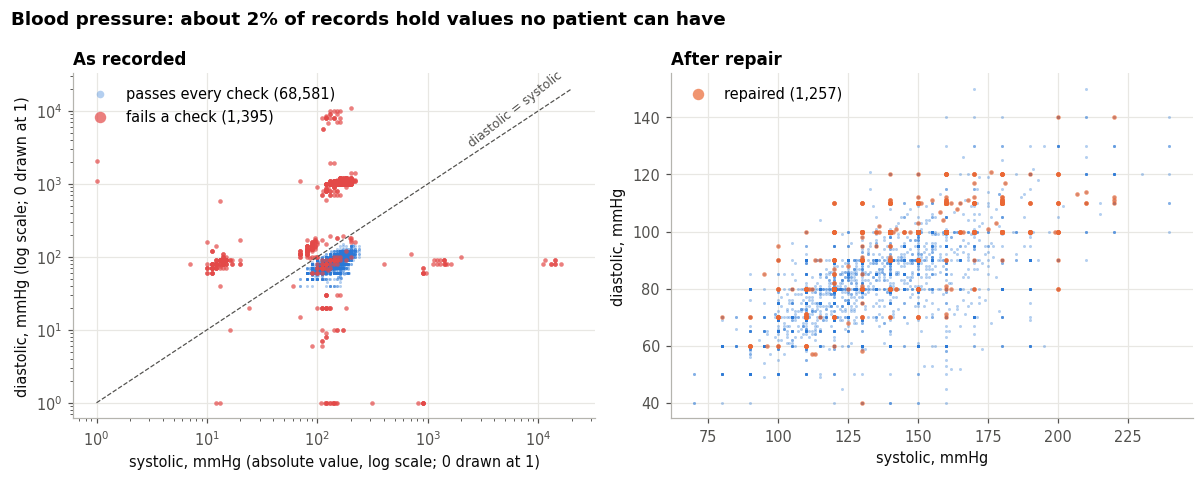

In [12]:
repaired, log = clean(raw, "repair")
bad = flags.any(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for mask, colour, label, size in [(~bad, NO_CVD, "passes every check", 4), (bad, FLAG, "fails a check", 9)]:
    d = deduped[mask]
    ax.scatter(d["ap_hi"].abs().clip(lower=1), d["ap_lo"].abs().clip(lower=1), s=size,
               color=colour, alpha=0.35 if colour == NO_CVD else 0.7, linewidths=0, label=f"{label} ({mask.sum():,})")
ax.set(xscale="log", yscale="log", xlabel="systolic, mmHg (absolute value, log scale; 0 drawn at 1)",
       ylabel="diastolic, mmHg (log scale; 0 drawn at 1)", title="As recorded")
ax.plot([1, 2e4], [1, 2e4], color=MUTED, lw=0.8, ls="--")
ax.annotate("diastolic = systolic", (2.2e3, 3.3e3), color=MUTED, fontsize=8, rotation=38)
ax.legend(loc="upper left", markerscale=2.5)

ax = axes[1]
ax.scatter(repaired["ap_hi"], repaired["ap_lo"], s=4, color=NO_CVD, alpha=0.35, linewidths=0)
fixed = repaired["id"].isin(log.loc[log["rule"] != "unrecoverable", "id"])
ax.scatter(repaired.loc[fixed, "ap_hi"], repaired.loc[fixed, "ap_lo"], s=9, color=CVD, alpha=0.7,
           linewidths=0, label=f"repaired ({fixed.sum():,})")
ax.set(xlabel="systolic, mmHg", ylabel="diastolic, mmHg", title="After repair")
ax.legend(loc="upper left", markerscale=2.5)
fig.suptitle("Blood pressure: about 2% of records hold values no patient can have", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_blood_pressure_cleaning.png")
plt.show()

The contradictory records are a smaller issue. Some records share every feature value but carry
different diagnoses:

In [13]:
features_only = deduped.drop(columns=["id", "cardio"])
groups = deduped.groupby(list(features_only.columns))["cardio"].nunique()
print(f"{(groups > 1).sum()} groups of records identical in every feature but with different diagnoses")

17 groups of records identical in every feature but with different diagnoses


These are kept. They are a reminder that the features do not determine the diagnosis: no model can
classify all of these records correctly.

### 4.2 Three cleaning strategies

Each strategy becomes its own training set (RQ2):

In [14]:
summary = cleaning_summary(raw)
summary.style.format({"share kept": "{:.1%}", "records": "{:,}"})

,records,duplicates removed,records repaired,implausible removed,share kept,description
strategy,,,,,,
raw,"69,976",24,0,0,100.0%,"no cleaning: exact duplicates removed, every value kept as recorded"
drop,"68,581",24,0,1395,98.0%,remove every record with an implausible value
repair,"69,838",24,1257,138,99.8%,"fix blood pressures with a recognisable entry error, then remove what is still implausible"


`repair` corrects a blood pressure only when a recognisable entry error explains it. It turns the
recorded value back into a plausible one with the rules shown above, applied in a fixed order: sign,
then unit, then extra digits, then swapped fields. Anything no rule recovers is removed, and so are
implausible heights and weights, whose errors show no pattern that would identify the true value.
Every change is logged:

In [15]:
print(log.groupby(["field", "rule"]).size().rename("values").to_string())
log[log["rule"] != "unrecoverable"].groupby("rule").head(3).sort_values("rule")

field        rule         
ap_hi        cmHg             179
             extra digits      38
             sign               7
             unrecoverable      5
ap_hi/ap_lo  swapped           94
ap_lo        cmHg              15
             extra digits     950
             sign               1
             unrecoverable     68


,id,field,before,after,rule
0,815,ap_hi,14,140,cmHg
1,1294,ap_hi,14,140,cmHg
2,1360,ap_hi,11,110,cmHg
6,2654,ap_hi,902,90,extra digits
7,2845,ap_hi,906,90,extra digits
26,6822,ap_hi,909,90,extra digits
24,6525,ap_hi,-100,100,sign
53,22881,ap_hi,-115,115,sign
65,29313,ap_hi,-100,100,sign
1263,681,ap_hi/ap_lo,120/150,150/120,swapped


The repairs are guesses, however well motivated. A recorded 906 may be 90 with a stray digit, or
96. This is why `repair` is compared against `drop`, which invents nothing, rather than silently
replacing it.

### 4.3 What cleaning changes

In [16]:
rows = []
for s in STRATEGIES:
    d, _ = clean(raw, s)
    rows.append({"strategy": s, "records": len(d),
                 "corr(systolic, cardio)": d["ap_hi"].corr(d["cardio"]),
                 "corr(diastolic, cardio)": d["ap_lo"].corr(d["cardio"]),
                 "mean systolic": d["ap_hi"].mean(), "max systolic": d["ap_hi"].max()})
pd.DataFrame(rows).set_index("strategy")

,records,"corr(systolic, cardio)","corr(diastolic, cardio)",mean systolic,max systolic
strategy,,,,,
raw,69976,0.054,0.066,128.820,16020
drop,68581,0.428,0.341,126.672,240
repair,69838,0.432,0.348,127.056,240


This is the most important number in the cleaning section. In the raw data, systolic blood pressure
has almost no linear relationship with the diagnosis (r = 0.05). After either kind of cleaning it is
the strongest single predictor (r = 0.43). Fewer than 2% of records cause this. A handful of values
in the thousands dominate the variance and hide everything else. Anything linear, such as a
correlation or a logistic regression on unscaled values, reads the raw data wrongly. Tree models
split on ranks and should suffer far less. Section 9 tests whether that holds.

## 5. Exploratory data analysis

From here on, the analysis uses the **training patients only**, cleaned with the `drop` strategy (the
choice of strategy is revisited in Section 9). The test patients stay unseen until Section 8.

The modelling table is built by the functions below. They convert units, add the derived features
explained in Section 6, and split the patients by the fixed train/test ids of Section 2.

In [17]:
def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """Readable units and codes: age in years, sex as male = 1.

    The documentation calls gender 'a categorical code'. Code 2 is male: its mean height is 8.5 cm
    above code 1 (169.9 vs 161.4 cm), the usual adult sex difference.
    """
    out = df.copy()
    out["age_years"] = out["age"] / 365.25
    out["male"] = (out["gender"] == 2).astype(int)
    return out.drop(columns=["age", "gender"])


def bp_stage(systolic: pd.Series, diastolic: pd.Series) -> pd.Series:
    """ACC/AHA 2017 category: the higher of the systolic and diastolic categories."""
    sys_stage = np.select([systolic >= 140, systolic >= 130, systolic >= 120], [3, 2, 1], 0)
    dia_stage = np.select([diastolic >= 90, diastolic >= 80], [3, 2], 0)
    return pd.Series(np.maximum(sys_stage, dia_stage), index=systolic.index)


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Clinically standard quantities derived from the recorded values."""
    out = df.copy()
    out["bmi"] = bmi(out)
    out["pulse_pressure"] = out["ap_hi"] - out["ap_lo"]
    out["mean_arterial_pressure"] = (out["ap_hi"] + 2 * out["ap_lo"]) / 3
    out["bp_stage"] = bp_stage(out["ap_hi"], out["ap_lo"])
    return out


def dataset(strategy: str = "drop", path: Path | str = DATA) -> pd.DataFrame:
    """Load, clean, prepare and derive features: the table every model is trained on."""
    cleaned, _ = clean(load(path), strategy)
    return add_features(prepare(cleaned))


def split_ids(df: pd.DataFrame, test_size: float = TEST_SIZE, seed: int = SEED) -> tuple[set, set]:
    """Train and test patient ids, drawn once from the deduplicated raw data, stratified by diagnosis.

    Every cleaning strategy is split by these same ids, so all of them are scored on the same patients.
    """
    from sklearn.model_selection import train_test_split

    d = deduplicate(df)
    train, test = train_test_split(d["id"], test_size=test_size, stratify=d[TARGET], random_state=seed)
    return set(train), set(test)


def train_test(strategy: str = "drop", path: Path | str = DATA) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The modelling table for one cleaning strategy, divided by the fixed train/test patient ids."""
    train_ids, test_ids = split_ids(load(path))
    data = dataset(strategy, path)
    return (data[data["id"].isin(train_ids)].reset_index(drop=True),
            data[data["id"].isin(test_ids)].reset_index(drop=True))

In [18]:
train, test = train_test("drop")
print(f"training patients: {len(train):,}   test patients: {len(test):,}")
print(f"share with CVD in training: {train['cardio'].mean():.1%}")
print(f"age {train['age_years'].min():.0f}-{train['age_years'].max():.0f} years, "
      f"median {train['age_years'].median():.0f}; {train['male'].mean():.0%} men")

training patients: 54,859   test patients: 13,722
share with CVD in training: 49.5%
age 30-65 years, median 54; 35% men


### 5.1 Disease rate by risk factor

The most direct way to see what the data holds is the share of patients with CVD at each level of
each factor. The dashed line marks the overall rate.

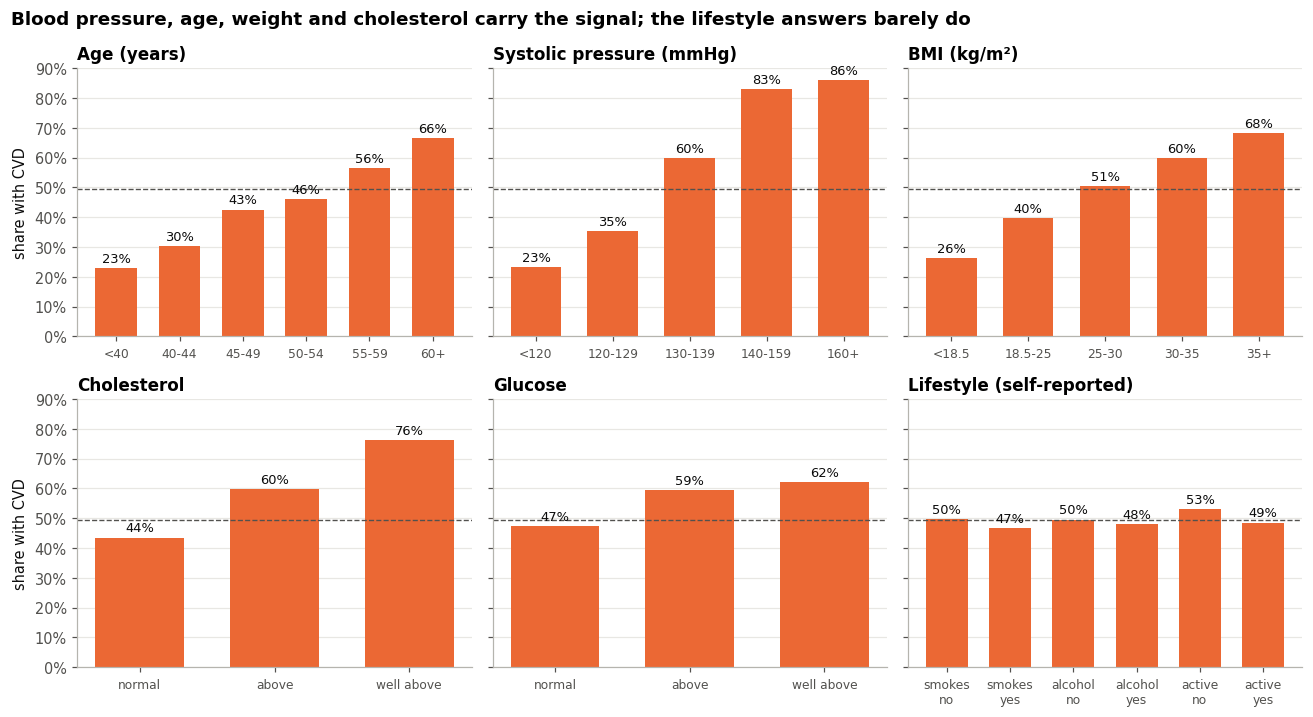

In [19]:
def band(series, edges, labels):
    return pd.cut(series, edges, labels=labels, right=False)

LEVELS = ["normal", "above", "well above"]
panels = [
    ("Age (years)", band(train["age_years"], [0, 40, 45, 50, 55, 60, 70],
                        ["<40", "40-44", "45-49", "50-54", "55-59", "60+"])),
    ("Systolic pressure (mmHg)", band(train["ap_hi"], [0, 120, 130, 140, 160, 400],
                                      ["<120", "120-129", "130-139", "140-159", "160+"])),
    ("BMI (kg/m²)", band(train["bmi"], [0, 18.5, 25, 30, 35, 100],
                         ["<18.5", "18.5-25", "25-30", "30-35", "35+"])),
    ("Cholesterol", pd.Categorical(train["cholesterol"].map(dict(enumerate(LEVELS, 1))), LEVELS)),
    ("Glucose", pd.Categorical(train["gluc"].map(dict(enumerate(LEVELS, 1))), LEVELS)),
]
lifestyle = [(f"{name}\n{answer}", train.loc[train[col] == value, "cardio"])
             for col, name in [("smoke", "smokes"), ("alco", "alcohol"), ("active", "active")]
             for value, answer in [(0, "no"), (1, "yes")]]
overall = train["cardio"].mean()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.6), sharey=True)
for ax, panel in zip(axes.flat, panels + [("Lifestyle (self-reported)", None)]):
    title, groups = panel
    if groups is None:
        labels = [name for name, _ in lifestyle]
        rates = [s.mean() for _, s in lifestyle]
    else:
        g = train.groupby(pd.Series(groups, index=train.index), observed=False)["cardio"].mean()
        labels, rates = list(g.index), list(g)
    x = np.arange(len(labels))
    ax.bar(x, rates, width=0.66, color=CVD)
    for xi, r in zip(x, rates):
        ax.text(xi, r + 0.02, f"{r:.0%}", ha="center", fontsize=8.5, color=INK)
    ax.axhline(overall, color=MUTED, lw=0.9, ls="--")
    ax.set_xticks(x, labels, fontsize=8)
    ax.set(title=title, ylim=(0, 0.9))
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for ax in axes[:, 0]:
    ax.set_ylabel("share with CVD")
fig.suptitle("Blood pressure, age, weight and cholesterol carry the signal; the lifestyle answers barely do",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig2_disease_rate_by_factor.png")
plt.show()

Four factors carry most of the signal, and each rises steadily with no reversal:

- **Systolic blood pressure** is the strongest. The disease rate climbs from about a quarter of
  patients below 120 mmHg to most patients at 160 mmHg and above.
- **Age.** The rate roughly triples between patients under 40 and those over 60.
- **Weight.** The rate rises across the BMI categories, from about a quarter of underweight patients
  to about two thirds of those with a BMI of 35 or more.
- **Cholesterol** is the strongest of the lab results. Three quarters of patients with "well above
  normal" cholesterol have CVD. Glucose follows the same pattern, but more weakly.

The three lifestyle answers barely move the rate, and two point the "wrong" way: smokers and drinkers
have slightly *lower* disease rates than other patients. Only physical activity has the expected
protective sign.

### 5.2 The smoking paradox

Smoking is an established cause of cardiovascular disease, so a lower rate among smokers needs an
explanation. The first suspect is a confounder. Smoking in this data is almost entirely male, so the
comparison is redone within each sex and age group:

share who smoke: {'women': '1.8%', 'men': '21.9%'}


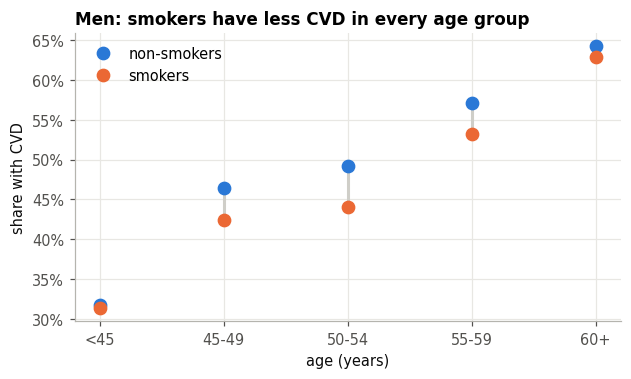

,non-smokers,smokers
age_years,,
<45,31.7%,31.3%
45-49,46.4%,42.4%
50-54,49.2%,44.1%
55-59,57.1%,53.2%
60+,64.2%,62.9%


In [20]:
print("share who smoke:", train.groupby("male")["smoke"].mean().rename({0: "women", 1: "men"})
      .map("{:.1%}".format).to_dict())

men = train[train["male"] == 1]
men_band = band(men["age_years"], [0, 45, 50, 55, 60, 70], ["<45", "45-49", "50-54", "55-59", "60+"])
by_age = men.groupby([men_band, "smoke"], observed=True)["cardio"].mean().unstack()
by_age.columns = ["non-smokers", "smokers"]

fig, ax = plt.subplots(figsize=(6.4, 3.4))
x = np.arange(len(by_age))
ax.vlines(x, by_age.min(axis=1), by_age.max(axis=1), color="#cfcec8", lw=2, zorder=1)
for col, colour in [("non-smokers", NO_CVD), ("smokers", CVD)]:
    ax.plot(x, by_age[col], "o", color=colour, ms=8, label=col, zorder=2)
ax.set_xticks(x, by_age.index)
ax.set(xlabel="age (years)", ylabel="share with CVD", title="Men: smokers have less CVD in every age group")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper left")
fig.savefig(FIGURES / "fig3_smoking_paradox.png")
plt.show()
by_age.style.format("{:.1%}")

The paradox survives both checks. Among men (women hardly smoke here), smokers have a lower disease
rate than non-smokers of the same age. The likeliest explanation lies in how the data was collected,
not in biology. The diagnosis and the answers were recorded **at the same examination**, so a patient
who already has heart disease has usually been told to quit. Such a patient answers "no" to smoking,
which moves diseased former smokers into the non-smoker group. This effect has a name in
epidemiology: the "sick quitter" [8].

This has two consequences for the rest of the study:

1. The task is **detection of an existing disease**, not prediction of a future one. A model trained
   here can say "this profile looks like the profiles of patients who have CVD". It cannot say "this
   person will develop CVD".
2. Feature effects learned from this data are **associations, not causes**. A model that gives
   smoking a negative weight is describing the data correctly, but no one should be told that smoking
   protects the heart. Section 8 returns to this when the model is explained.

### 5.3 Correlations between features

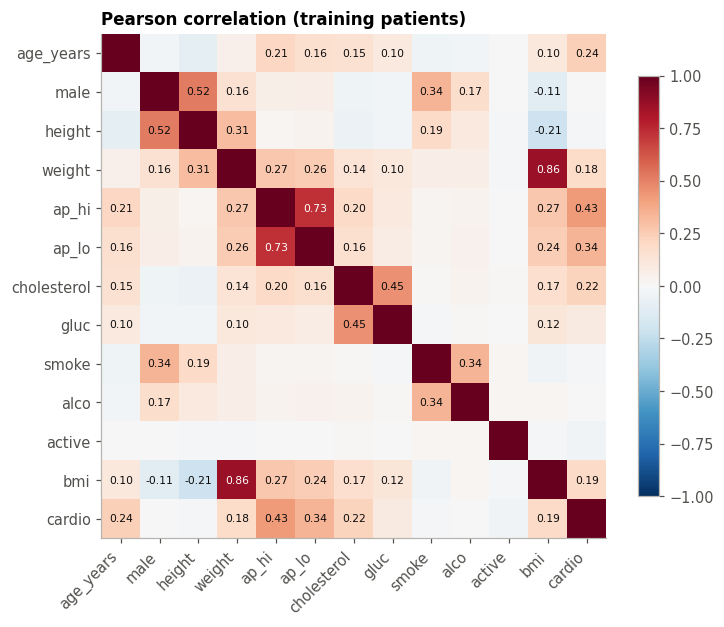

,correlation with CVD
ap_hi,0.427
ap_lo,0.339
age_years,0.240
cholesterol,0.222
bmi,0.193
weight,0.183
gluc,0.093
male,0.007
alco,-0.006
height,-0.012


In [21]:
cols = BASE_FEATURES + ["bmi", "cardio"]
corr = train[cols].corr()

fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        if i != j and abs(v) >= 0.1:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
ax.set_title("Pearson correlation (training patients)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGURES / "fig4_correlations.png")
plt.show()
corr["cardio"].drop("cardio").sort_values(ascending=False).rename("correlation with CVD").to_frame()

The last column restates Section 5.1 as single numbers. Systolic pressure, diastolic pressure, age,
cholesterol and BMI lead, while sex and the lifestyle answers are close to zero. Among the features
themselves, the two blood pressures are strongly correlated (about 0.7), and so are weight and BMI,
and sex and height. For tree models this hardly matters. For logistic regression it means individual
coefficients must be read with care, since correlated features share their effect.

### 5.4 What the exploration implies for modelling

- The strongest relationships are **monotonic**: the risk rises steadily with blood pressure, age,
  BMI and cholesterol. A linear model on suitable features should capture most of the signal, so
  flexible models have limited room to improve on it. This is the expectation Q1 will test.
- **No class imbalance**: 49.5% of training patients have CVD. Oversampling methods such as SMOTE
  have nothing to fix here. In Section 9 they appear only as one of the mistakes the leakage
  experiments reproduce.
- The lifestyle answers are weak and partly distorted by reverse causation. They are kept, because a
  model should use what the examination records, but nothing causal is read into them.

## 6. Feature engineering

Four clinically standard quantities are added to the eleven recorded ones:

| Feature | Definition | Why |
|---|---|---|
| `bmi` | weight / height² (kg/m²) | the usual measure of excess weight; height and weight alone do not express it |
| `pulse_pressure` | systolic − diastolic | a marker of arterial stiffness |
| `mean_arterial_pressure` | (systolic + 2 × diastolic) / 3 | average pressure over the cardiac cycle |
| `bp_stage` | ACC/AHA 2017: 0 normal, 1 elevated, 2 stage 1, 3 stage 2 | the categories clinicians act on |

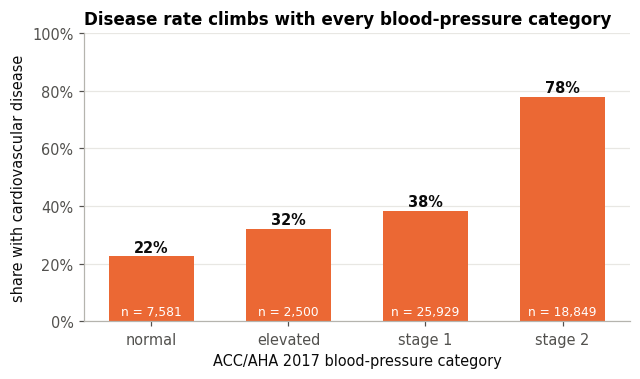

In [22]:
rate = train.groupby("bp_stage")["cardio"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(range(4), rate["mean"], width=0.62, color=CVD)
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    ax.text(i, m + 0.015, f"{m:.0%}", ha="center", color=INK, fontsize=9.5, fontweight="bold")
    ax.text(i, 0.02, f"n = {n:,}", ha="center", color="white", fontsize=8)
ax.set_xticks(range(4), BP_STAGE_NAMES)
ax.set(ylim=(0, 1), ylabel="share with cardiovascular disease", xlabel="ACC/AHA 2017 blood-pressure category",
       title="Disease rate climbs with every blood-pressure category")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "fig5_disease_by_bp_stage.png")
plt.show()

The large stage 1 group follows from the guideline, not from an error. The most common reading in
the data, 120/80, is stage 1 because a diastolic pressure of 80 mmHg starts stage 1 in the 2017
guideline.

The derived category summarises both pressures in the terms clinicians act on, and the disease rate
rises steadily across it: from about one patient in five at normal pressure to most patients at
stage 2.

Two points about these features:

- **They are fixed formulas, not learned transformations.** Like the cleaning rules, they cannot
  leak test information.
- **They overlap with the recorded values on purpose.** BMI is a function of height and weight, and
  the three pressure features are functions of the two readings. Tree models gain from having the
  combination precomputed, since a split on BMI replaces many splits on height and weight. For
  logistic regression the overlap is handled by regularisation. Section 7 checks whether the derived
  features help at all, by training the same models with and without them.
## 7. Models

### 7.1 What is compared

Every candidate is evaluated with 5-fold cross-validation on the training patients, using the same
five folds. All models are implemented with scikit-learn [12]. The test patients are not touched in this section.

| Candidate | Type | What it uses | Settings searched |
|---|---|---|---|
| Rule: systolic ≥ 130 mmHg | clinical baseline | one reading, guideline threshold | none |
| Systolic pressure alone | clinical baseline | one reading; cut-off chosen on the training folds | none |
| Framingham (published) | clinical baseline | age, sex, BMI, systolic pressure, smoking, diabetes | none: the 2008 equations as published |
| Framingham form (refit) | logistic regression | the same terms, one equation per sex | coefficients refitted on these patients |
| Logistic regression | linear model | all 15 features, standardised | regularisation strength C |
| Random forest | tree ensemble | all 15 features | leaf size, features per split |
| Gradient boosting | tree ensemble (histogram GBDT) | all 15 features | learning rate, tree size, leaf size |
| Neural network (MLP) | multilayer perceptron | all 15 features, standardised | layer sizes, weight decay |

Some notes on the baselines:

- **The Framingham score answers a different question.** It was built to predict a *first*
  cardiovascular event over the next ten years in people free of CVD, while this dataset records
  existing disease. The dataset also has no field for blood-pressure treatment, so the equation for
  untreated patients is used, and no diabetes field, so glucose "well above normal" stands in for
  diabetes. Using its risk to rank these patients is therefore a reference point, not a fair contest.
  The refitted version keeps Framingham's functional form but learns the weights from these
  patients. It shows how much of any gap comes from the form and how much from the population.
- **Two baselines need a cut-off.** Systolic pressure alone and the published Framingham risk are
  continuous scores, so the cut-off that classifies the four training folds most accurately is
  applied to the fifth. Their AUC needs no cut-off.

**Selection rule, fixed in advance.** The final model is the *simplest* machine-learning model whose
mean cross-validated AUC is within one standard error of the best one. The order of simplicity is:
Framingham form, logistic regression, gradient boosting, random forest, neural network. A difference
smaller than the fold-to-fold noise is not evidence, so it should not buy complexity.

### 7.2 Cross-validated comparison

The baselines and models of Section 7.1, and the cross-validated comparison that scores them all on
the same five folds:

In [23]:
# Framingham general cardiovascular risk, office-based model (BMI instead of cholesterol), for
# patients not treated for hypertension (D'Agostino et al., Circulation 2008):
#     10-year risk = 1 - s0 ** exp(sum(coefficient * term) - mean)
FRAMINGHAM = {
    0: {"ln_age": 2.72107, "ln_bmi": 0.51125, "ln_sbp": 2.81291, "smoke": 0.61868, "diabetes": 0.77763,
        "s0": 0.94833, "mean": 26.0145},   # women
    1: {"ln_age": 3.11296, "ln_bmi": 0.79277, "ln_sbp": 1.85508, "smoke": 0.70953, "diabetes": 0.53160,
        "s0": 0.88431, "mean": 23.9388},   # men
}
SBP_RULE = 130  # mmHg: stage 1 hypertension (ACC/AHA 2017)


def diabetes_proxy(df: pd.DataFrame) -> pd.Series:
    """The dataset has no diabetes field; glucose 'well above normal' is the closest stand-in."""
    return (df["gluc"] == 3).astype(int)


def framingham_terms(df: pd.DataFrame) -> np.ndarray:
    """ln age, ln BMI, ln systolic pressure, smoking and diabetes: the Framingham office model's inputs."""
    return np.column_stack([np.log(df["age_years"]), np.log(df["bmi"]), np.log(df["ap_hi"]),
                            df["smoke"], diabetes_proxy(df)])


def framingham_risk(df: pd.DataFrame) -> pd.Series:
    """Published Framingham 10-year CVD risk, as a clinician would compute it, with nothing refitted."""
    terms = framingham_terms(df)
    risk = np.empty(len(df))
    for male, c in FRAMINGHAM.items():
        rows = df["male"].to_numpy() == male
        beta = np.array([c["ln_age"], c["ln_bmi"], c["ln_sbp"], c["smoke"], c["diabetes"]])
        risk[rows] = 1 - c["s0"] ** np.exp(terms[rows] @ beta - c["mean"])
    return pd.Series(risk, index=df.index)


def framingham_design(df: pd.DataFrame) -> np.ndarray:
    """Framingham's terms once for women and once for men, plus a sex indicator, so that a logistic
    regression refits the published model's two equations on this population."""
    male = df["male"].to_numpy()[:, None]
    terms = framingham_terms(df)
    return np.column_stack([terms * (1 - male), terms * male, male])

In [24]:
N_JOBS = int(os.environ.get("CARDIO_JOBS", "4"))
CV_FOLDS = 5
# Simplest first: when several models are statistically tied, the earliest in this order is chosen
SIMPLICITY = ["Framingham form (refit)", "Logistic regression", "Gradient boosting", "Random forest",
              "Neural network (MLP)"]


def cv_splitter(seed: int = SEED):
    from sklearn.model_selection import StratifiedKFold
    return StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)


def model_specs() -> dict[str, tuple]:
    """Each model with the hyperparameter grid that cross-validation searches."""
    from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.neural_network import MLPClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import FunctionTransformer, StandardScaler

    def scaled(name, model):
        return Pipeline([("scale", StandardScaler()), (name, model)])

    return {
        "Framingham form (refit)": (
            Pipeline([("terms", FunctionTransformer(framingham_design)), ("scale", StandardScaler()),
                      ("lr", LogisticRegression(max_iter=5000))]),
            {"lr__C": [1.0]}),
        "Logistic regression": (
            scaled("lr", LogisticRegression(max_iter=5000)),
            {"lr__C": [0.01, 0.1, 1.0, 10.0]}),
        "Random forest": (
            RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
            {"min_samples_leaf": [10, 30, 100], "max_features": ["sqrt", 0.5]}),
        "Gradient boosting": (
            # early stopping on 10% of the training data (sklearn's default above 10,000 rows) ends
            # the boosting long before max_iter at the larger learning rates
            HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED),
            {"learning_rate": [0.01, 0.03, 0.1], "max_leaf_nodes": [7, 15, 31],
             "min_samples_leaf": [20, 50, 200]}),
        "Neural network (MLP)": (
            scaled("mlp", MLPClassifier(early_stopping=True, max_iter=300, random_state=SEED)),
            {"mlp__hidden_layer_sizes": [(32,), (64, 32), (128, 64)], "mlp__alpha": [1e-5, 1e-4, 1e-2]}),
    }


def classification_metrics(y, score, threshold: float) -> dict:
    """AUC from the score; accuracy, sensitivity and specificity from score >= threshold."""
    from sklearn.metrics import roc_auc_score

    y = np.asarray(y)
    pred = np.asarray(score) >= threshold
    return {"auc": roc_auc_score(y, score), "accuracy": (pred == y).mean(),
            "sensitivity": pred[y == 1].mean(), "specificity": (~pred[y == 0]).mean()}


def accuracy_threshold(y, score) -> float:
    """The cut-off on a score that classifies the given (training) patients most accurately."""
    y, score = np.asarray(y), np.asarray(score)
    candidates = np.unique(np.quantile(score, np.linspace(0.01, 0.99, 197)))
    return candidates[np.argmax([((score >= t) == y).mean() for t in candidates])]


def compare_models(train: pd.DataFrame, features: list[str] = FEATURES, specs: dict | None = None,
                   n_jobs: int = N_JOBS) -> tuple[pd.DataFrame, dict]:
    """Cross-validated comparison of the clinical baselines and the machine-learning models.

    Everything is scored on the same five validation folds of the training patients. The baselines
    fit nothing; where a baseline needs a cut-off (systolic pressure alone, published Framingham risk),
    it is chosen on the other four folds. Each model's grid is searched by AUC, and its row reports
    the best setting. Returns the table and the fitted searches (refitted on all training patients).
    """
    from sklearn.metrics import make_scorer, recall_score
    from sklearn.model_selection import GridSearchCV

    X, y = train[features], train[TARGET]
    cv = cv_splitter()
    rows = []
    baselines = [
        (f"Rule: systolic ≥ {SBP_RULE} mmHg", (train["ap_hi"] >= SBP_RULE).astype(float), 0.5),
        ("Systolic pressure alone", train["ap_hi"].astype(float), None),
        ("Framingham (published)", framingham_risk(train), None),
    ]
    for name, score, fixed in baselines:
        folds = []
        for tr, va in cv.split(X, y):
            cut = fixed if fixed is not None else accuracy_threshold(y.iloc[tr], score.iloc[tr])
            folds.append(classification_metrics(y.iloc[va], score.iloc[va], cut))
        f = pd.DataFrame(folds)
        rows.append({"model": name, "kind": "clinical baseline", "auc": f["auc"].mean(), "auc_sd": f["auc"].std(),
                     **f[["accuracy", "sensitivity", "specificity"]].mean().to_dict(),
                     "best setting": "-" if fixed is not None else "cut-off chosen on training folds",
                     "fit seconds": 0.0})

    scoring = {"auc": "roc_auc", "accuracy": "accuracy", "sensitivity": make_scorer(recall_score),
               "specificity": make_scorer(recall_score, pos_label=0)}
    searches = {}
    for name, (estimator, grid) in (specs or model_specs()).items():
        search = GridSearchCV(estimator, grid, scoring=scoring, refit="auc", cv=cv, n_jobs=n_jobs)
        search.fit(X, y)
        r, i = search.cv_results_, search.best_index_
        rows.append({"model": name, "kind": "machine learning", "auc": r["mean_test_auc"][i],
                     "auc_sd": r["std_test_auc"][i],
                     **{m: r[f"mean_test_{m}"][i] for m in ("accuracy", "sensitivity", "specificity")},
                     "best setting": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in search.best_params_.items()),
                     "fit seconds": r["mean_fit_time"][i]})
        searches[name] = search
    return pd.DataFrame(rows).set_index("model"), searches


def choose_model(table: pd.DataFrame) -> str:
    """The simplest machine-learning model whose CV AUC is within one standard error of the best.

    Differences smaller than the fold-to-fold noise are not evidence that one model is better, so they
    should not buy complexity (the 'one-standard-error rule').
    """
    ml = table[table["kind"] == "machine learning"]
    best = ml["auc"].idxmax()
    margin = ml.loc[best, "auc_sd"] / math.sqrt(CV_FOLDS)
    tied = ml.index[ml["auc"] >= ml.loc[best, "auc"] - margin]
    return min(tied, key=SIMPLICITY.index)


def feature_set_comparison(train: pd.DataFrame, searches: dict, names: list[str],
                           n_jobs: int = N_JOBS) -> pd.DataFrame:
    """CV AUC of the chosen settings with the recorded features only, and with the derived ones too."""
    from sklearn.base import clone
    from sklearn.model_selection import cross_val_score

    rows = []
    for name in names:
        for label, cols in (("recorded only", BASE_FEATURES), ("recorded + derived", FEATURES)):
            s = cross_val_score(clone(searches[name].best_estimator_), train[cols], train[TARGET],
                                cv=cv_splitter(), scoring="roc_auc", n_jobs=n_jobs)
            rows.append({"model": name, "features": label, "auc": s.mean(), "auc_sd": s.std(ddof=1)})
    return pd.DataFrame(rows).pivot(index="model", columns="features", values="auc")


def learning_curve_auc(train: pd.DataFrame, estimators: dict,
                       sizes: tuple = (0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 1.0),
                       n_jobs: int = N_JOBS) -> pd.DataFrame:
    """Validation AUC as the number of training patients grows (sizes are shares of a training fold):
    does the model run out of data, or of information in the features?"""
    from sklearn.base import clone
    from sklearn.model_selection import learning_curve

    rows = []
    for name, est in estimators.items():
        n, _, val = learning_curve(clone(est), train[FEATURES], train[TARGET], train_sizes=list(sizes),
                                   cv=cv_splitter(), scoring="roc_auc", n_jobs=n_jobs, shuffle=True,
                                   random_state=SEED)
        rows += [{"model": name, "patients": k, "auc": v.mean(), "auc_sd": v.std(ddof=1)} for k, v in zip(n, val)]
    return pd.DataFrame(rows)

In [25]:
import time

t0 = time.time()
comparison, searches = compare_models(train)
print(f"{len(searches)} grid searches and 3 baselines, {CV_FOLDS}-fold CV: {time.time() - t0:.0f} s")
(comparison.sort_values("auc", ascending=False)
 .style.format({"auc": "{:.4f}", "auc_sd": "{:.4f}", "accuracy": "{:.1%}", "sensitivity": "{:.1%}",
                "specificity": "{:.1%}", "fit seconds": "{:.1f}"}))

5 grid searches and 3 baselines, 5-fold CV: 243 s


,kind,auc,auc_sd,accuracy,sensitivity,specificity,best setting,fit seconds
model,,,,,,,,
Gradient boosting,machine learning,0.8005,0.0026,73.5%,69.1%,77.8%,"learning_rate=0.01, max_leaf_nodes=15, min_samples_leaf=50",3.1
Random forest,machine learning,0.7992,0.0028,73.3%,68.4%,78.2%,"max_features=sqrt, min_samples_leaf=30",7.0
Neural network (MLP),machine learning,0.7986,0.0020,73.3%,69.6%,76.9%,"alpha=0.01, hidden_layer_sizes=(128, 64)",4.8
Logistic regression,machine learning,0.7902,0.0026,72.7%,67.1%,78.3%,C=0.1,0.1
Framingham form (refit),machine learning,0.7798,0.0034,71.8%,67.1%,76.5%,C=1.0,0.2
Systolic pressure alone,clinical baseline,0.7506,0.0035,71.3%,61.8%,80.7%,cut-off chosen on training folds,0.0
Rule: systolic ≥ 130 mmHg,clinical baseline,0.7121,0.0037,71.3%,61.8%,80.7%,-,0.0
Framingham (published),clinical baseline,0.6962,0.0031,65.2%,75.4%,55.2%,cut-off chosen on training folds,0.0


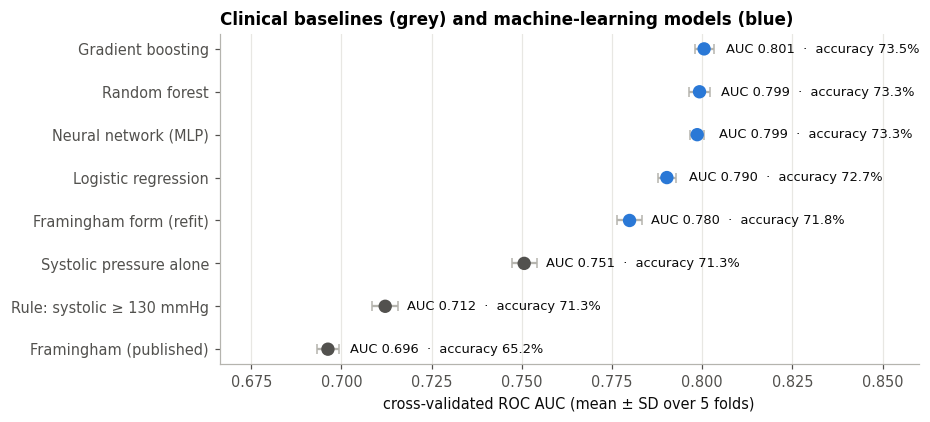

In [26]:
order = comparison.sort_values("auc")
fig, ax = plt.subplots(figsize=(8.2, 3.9))
y = np.arange(len(order))
colours = [NO_CVD if k == "machine learning" else MUTED for k in order["kind"]]
ax.errorbar(order["auc"], y, xerr=order["auc_sd"], fmt="none", ecolor="#b5b4ae", elinewidth=1.5, capsize=3)
ax.scatter(order["auc"], y, s=60, color=colours, zorder=3)
for yi, (auc, acc) in enumerate(zip(order["auc"], order["accuracy"])):
    ax.text(auc + 0.006, yi, f"AUC {auc:.3f}  ·  accuracy {acc:.1%}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, order.index)
ax.set(xlabel="cross-validated ROC AUC (mean ± SD over 5 folds)", xlim=(order["auc"].min() - 0.03, 0.86),
       title="Clinical baselines (grey) and machine-learning models (blue)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "fig6_model_comparison.png")
plt.show()

**Every machine-learning model beats every clinical baseline, but the margins are small.**

- **Best model.** Gradient boosting reaches a cross-validated AUC of 0.800 and an accuracy of
  73.5%. The guideline rule (systolic ≥ 130 mmHg) is right for 71.3% of patients. Out of every 1,000
  patients, the best model classifies about 22 more correctly than one blood-pressure reading.
- **The flexible models are tied.** Gradient boosting, random forest and the neural network lie
  within 0.002 AUC of each other, close to the fold-to-fold standard deviation (about 0.003).
  Logistic regression is 0.010 behind, so the interactions and curves that trees and networks can
  represent are worth a little, but only a little.
- **The guideline's threshold is the best cut-off.** When systolic pressure alone is given the
  cut-off that classifies the training folds most accurately, the data chooses 130 mmHg, the
  guideline's own value: the accuracy, sensitivity and specificity are identical to the rule's. The
  AUC differs only because the rule turns the reading into a yes/no answer.
- **The published Framingham score ranks these patients worse than systolic pressure alone**
  (AUC 0.696 vs 0.751). Refitting the same five terms on these patients raises it to 0.780. The
  functional form is sound; its weights do not transfer to a different population and a different
  question (existing disease here, a first event within ten years in Framingham). A risk score
  carried over to a new population has to be recalibrated before its numbers mean anything.

The cross-validated score of each model's *best* setting is slightly optimistic, because that
setting was chosen on the same folds. With grids this small and 55,000 patients the bias is tiny, but
it is one reason the test set in Section 8 has the final word.

### 7.3 Do the derived features help?

Section 6 added BMI, pulse pressure, mean arterial pressure and the blood-pressure stage. Here the
best settings of logistic regression and gradient boosting are cross-validated again, with and
without them:

In [27]:
features_effect = feature_set_comparison(train, searches, ["Logistic regression", "Gradient boosting"])
features_effect["gain"] = features_effect["recorded + derived"] - features_effect["recorded only"]
features_effect.style.format("{:.4f}")

features,recorded + derived,recorded only,gain
model,,,
Gradient boosting,0.8005,0.8003,0.0003
Logistic regression,0.7902,0.7907,-0.0005


The derived features change the AUC by less than 0.001 in either direction. That is well inside the
noise. Both models can build what they need from the recorded values on their own, which is a common
finding with tabular data this simple. The derived features stay in the final model anyway: they
cost nothing in accuracy, and they make the explanations in Section 8 easier to read. A clinician
thinks in BMI and blood-pressure stages, not in height and weight.

### 7.4 Would more data help?

The same models are trained on growing shares of a training fold. If the curve is still rising at
the full training set, more patients would help. If it is flat, the limit lies in the features.

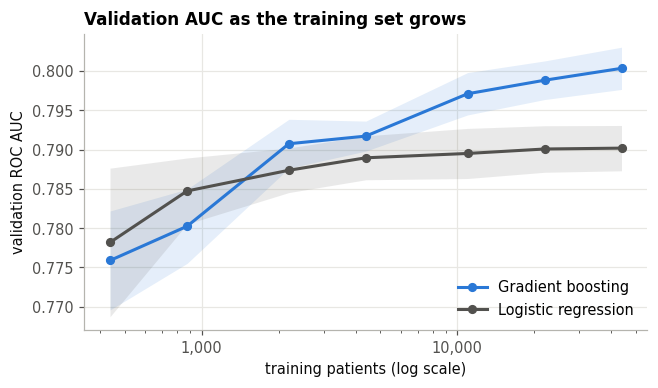

model,Gradient boosting,Logistic regression
patients,,
438,0.7759,0.7782
877,0.7802,0.7847
2194,0.7907,0.7874
4388,0.7917,0.7890
10971,0.7971,0.7895
21943,0.7988,0.7901
43887,0.8003,0.7902


In [28]:
curve = learning_curve_auc(train, {name: searches[name].best_estimator_
                                          for name in ["Logistic regression", "Gradient boosting"]})
fig, ax = plt.subplots(figsize=(6.6, 3.5))
for name, g in curve.groupby("model"):
    colour = NO_CVD if name == "Gradient boosting" else MUTED
    ax.plot(g["patients"], g["auc"], "-o", color=colour, lw=2, ms=5, label=name)
    ax.fill_between(g["patients"], g["auc"] - g["auc_sd"], g["auc"] + g["auc_sd"], color=colour, alpha=0.12, lw=0)
ax.set(xscale="log", xlabel="training patients (log scale)", ylabel="validation ROC AUC",
       title="Validation AUC as the training set grows")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(loc="lower right")
fig.savefig(FIGURES / "fig7_learning_curve.png")
plt.show()
curve.pivot(index="patients", columns="model", values="auc").style.format("{:.4f}")

The two curves tell different stories:

- **Logistic regression has learned all it can from about 2,000 patients.** Its validation AUC moves
  by only 0.003 between 2,000 and 44,000 patients.
- **Gradient boosting needs more data, then slows down.** It needs more patients to estimate its
  interactions, overtakes logistic regression at around 2,000 patients, and keeps improving. But the
  last doubling, from 22,000 to 44,000 patients, adds only 0.0015.

More patients of the same kind would therefore add very little. **The ceiling of about 0.80 AUC (73%
accuracy) is set by the information in the eleven recorded values, not by the amount of data or the
choice of algorithm.** Widening the search grids points the same way. The first run placed the best
gradient-boosting and neural-network settings at the edge of their grids, so the grids were
extended. Both models moved by less than 0.0005 AUC, so they sit on a plateau.

### 7.5 The chosen model

In [29]:
chosen = choose_model(comparison)
ml = comparison[comparison["kind"] == "machine learning"]
best = ml["auc"].idxmax()
print(f"best cross-validated AUC: {best} ({ml.loc[best, 'auc']:.4f} ± {ml.loc[best, 'auc_sd']:.4f})")
print(f"one standard error: {ml.loc[best, 'auc_sd'] / np.sqrt(CV_FOLDS):.4f}")
print(f"chosen by the one-standard-error rule: {chosen} ({ml.loc[chosen, 'auc']:.4f}), "
      f"setting: {ml.loc[chosen, 'best setting']}")

best cross-validated AUC: Gradient boosting (0.8005 ± 0.0026)
one standard error: 0.0012
chosen by the one-standard-error rule: Gradient boosting (0.8005), setting: learning_rate=0.01, max_leaf_nodes=15, min_samples_leaf=50


Gradient boosting has the best cross-validated AUC, and no simpler model comes within one standard
error of it. Random forest misses by 0.0013 against a margin of 0.0012, a near tie, but the rule was
fixed in advance, and gradient boosting is also faster to train. **Gradient boosting is the final
model.** The next section scores it, and every other candidate, once on the test patients.

## 8. The final model on the test set

### 8.1 Every candidate, scored once

The 13,722 test patients have not been used for anything so far. Each candidate is scored on them
exactly once:

- The machine-learning models use their selected settings, refitted on all training patients.
- The baselines that need a cut-off use the one chosen on the training patients.
- AUC confidence intervals come from 2,000 bootstrap resamples of the test patients.

The helpers for the test-set evaluation: paired bootstrap intervals, out-of-fold predictions and the
screening cut-off.

In [30]:
def bootstrap(y, scores: dict, statistic, n: int = 2000, seed: int = SEED) -> pd.DataFrame:
    """Percentile bootstrap of statistic(y, score) for several scores, resampling the same patients
    for all of them, so differences between scores can be bootstrapped too. One row per resample."""
    y = np.asarray(y)
    scores = {k: np.asarray(v) for k, v in scores.items()}
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        rows.append({k: statistic(y[idx], s[idx]) for k, s in scores.items()})
    return pd.DataFrame(rows)


def interval(samples: pd.Series, level: float = 0.95) -> tuple[float, float]:
    a = (1 - level) / 2
    return float(samples.quantile(a)), float(samples.quantile(1 - a))


def out_of_fold(estimator, train: pd.DataFrame, features: list[str] = FEATURES,
                n_jobs: int = N_JOBS) -> np.ndarray:
    """Each training patient's predicted risk from a model that did not see that patient."""
    from sklearn.base import clone
    from sklearn.model_selection import cross_val_predict

    return cross_val_predict(clone(estimator), train[features], train[TARGET], cv=cv_splitter(),
                             method="predict_proba", n_jobs=n_jobs)[:, 1]


def screening_threshold(y, risk, sensitivity: float = 0.80) -> float:
    """The highest cut-off that still detects at least `sensitivity` of the diseased patients."""
    y, risk = np.asarray(y), np.asarray(risk)
    sick = np.sort(risk[y == 1])
    return float(sick[int(math.floor((1 - sensitivity) * len(sick)))])

In [31]:
from sklearn.metrics import roc_auc_score

final = searches[chosen].best_estimator_
y_test = test["cardio"]
test_scores = {
    f"Rule: systolic ≥ {SBP_RULE} mmHg": (test["ap_hi"] >= SBP_RULE).astype(float),
    "Systolic pressure alone": test["ap_hi"].astype(float),
    "Framingham (published)": framingham_risk(test),
    **{name: s.predict_proba(test[FEATURES])[:, 1] for name, s in searches.items()},
}
cutoffs = {name: 0.5 for name in test_scores}
cutoffs["Systolic pressure alone"] = accuracy_threshold(train["cardio"], train["ap_hi"])
cutoffs["Framingham (published)"] = accuracy_threshold(train["cardio"], framingham_risk(train))

auc_boot = bootstrap(y_test, test_scores, roc_auc_score)
rows = []
for name, score in test_scores.items():
    m = classification_metrics(y_test, score, cutoffs[name])
    lo, hi = interval(auc_boot[name])
    rows.append({"model": name, "test AUC": m["auc"], "95% CI": f"{lo:.3f}-{hi:.3f}",
                 "CV AUC": comparison.loc[name, "auc"], "accuracy": m["accuracy"],
                 "sensitivity": m["sensitivity"], "specificity": m["specificity"]})
test_table = pd.DataFrame(rows).set_index("model").sort_values("test AUC", ascending=False)
test_table.to_csv(ROOT / "outputs" / "test_results.csv")
test_table.style.format({"test AUC": "{:.3f}", "CV AUC": "{:.3f}", "accuracy": "{:.1%}",
                         "sensitivity": "{:.1%}", "specificity": "{:.1%}"})

,test AUC,95% CI,CV AUC,accuracy,sensitivity,specificity
model,,,,,,
Gradient boosting,0.804,0.797-0.811,0.801,73.6%,68.9%,78.2%
Random forest,0.803,0.796-0.810,0.799,73.4%,68.5%,78.1%
Neural network (MLP),0.803,0.795-0.810,0.799,73.4%,71.0%,75.7%
Logistic regression,0.793,0.785-0.800,0.790,72.6%,66.8%,78.2%
Framingham form (refit),0.780,0.773-0.788,0.780,71.4%,66.3%,76.3%
Systolic pressure alone,0.754,0.746-0.761,0.751,71.3%,61.8%,80.6%
Rule: systolic ≥ 130 mmHg,0.712,0.704-0.719,0.712,71.3%,61.8%,80.6%
Framingham (published),0.693,0.684-0.701,0.696,64.6%,74.0%,55.5%


**The test set confirms the cross-validation.** Every candidate's test AUC is within 0.004 of its
cross-validated AUC, and the ranking is unchanged. The models did not overfit, and choosing settings
on the cross-validation folds did not flatter them. On patients it has never seen, gradient boosting
reaches an AUC of 0.804 (95% CI 0.797-0.811) and 73.6% accuracy, against 71.3% for the
systolic ≥ 130 rule.

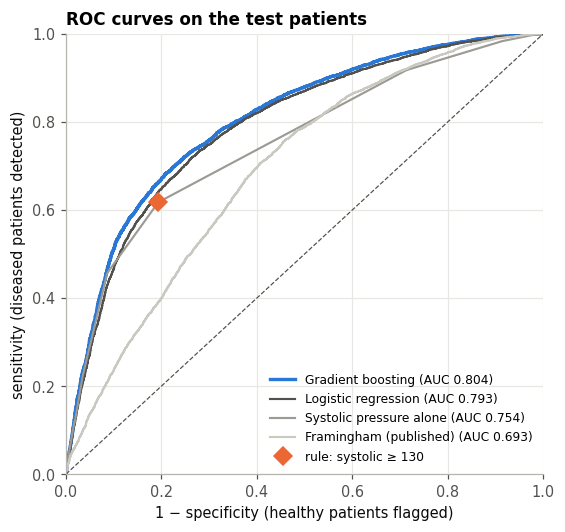

In [32]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5.6, 5.2))
for name, colour, lw in [(chosen, NO_CVD, 2.2), ("Logistic regression", MUTED, 1.4),
                         ("Systolic pressure alone", "#9b9a94", 1.4), ("Framingham (published)", "#c9c8c1", 1.4)]:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    ax.plot(fpr, tpr, color=colour, lw=lw, label=f"{name} (AUC {roc_auc_score(y_test, test_scores[name]):.3f})")
rule = classification_metrics(y_test, test_scores[f"Rule: systolic ≥ {SBP_RULE} mmHg"], 0.5)
ax.plot(1 - rule["specificity"], rule["sensitivity"], "D", color=CVD, ms=8, label=f"rule: systolic ≥ {SBP_RULE}")
ax.plot([0, 1], [0, 1], ls="--", lw=0.8, color=MUTED)
ax.set(xlabel="1 − specificity (healthy patients flagged)", ylabel="sensitivity (diseased patients detected)",
       title="ROC curves on the test patients", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", fontsize=8)
fig.savefig(FIGURES / "fig8_roc_test.png")
plt.show()

The rule is one point on the ROC plane; the model is a whole curve. Holding the rule's specificity
fixed shows what the model adds at that point:

In [33]:
rule_spec = rule["specificity"]
fpr, tpr, thresholds = roc_curve(y_test, test_scores[chosen])
at_rule = tpr[np.searchsorted(fpr, 1 - rule_spec, side="right") - 1]
n_sick = int(y_test.sum())
print(f"at the rule's specificity ({rule_spec:.1%}): rule detects {rule['sensitivity']:.1%} of diseased patients, "
      f"{chosen.lower()} {at_rule:.1%}")
print(f"that is {round((at_rule - rule['sensitivity']) * n_sick):,} more of the {n_sick:,} diseased test patients, "
      f"with the same number of healthy patients flagged")

at the rule's specificity (80.6%): rule detects 61.8% of diseased patients, gradient boosting 66.2%
that is 301 more of the 6,785 diseased test patients, with the same number of healthy patients flagged


At the rule's own operating point, the model finds 66.2% of the diseased patients instead of 61.8%:
301 more of the 6,785 diseased test patients, with no extra healthy patients flagged. This is the
most concrete form of the answer to Q1. The gain is real but modest, about one more patient detected
for every 23 diseased patients examined.

### 8.2 Are the differences real?

The same bootstrap resamples score every model, so each AUC difference can be given its own
interval. If an interval excludes zero, the difference is unlikely to be chance.

In [34]:
pairs = [(chosen, other) for other in ["Random forest", "Neural network (MLP)", "Logistic regression",
                                        "Framingham form (refit)", "Systolic pressure alone"]]
diffs = []
for a, b in pairs:
    d = auc_boot[a] - auc_boot[b]
    lo, hi = interval(d)
    diffs.append({"comparison": f"{a} − {b}", "AUC difference": roc_auc_score(y_test, test_scores[a])
                  - roc_auc_score(y_test, test_scores[b]), "95% CI": f"{lo:+.4f} to {hi:+.4f}",
                  "excludes zero": lo > 0 or hi < 0})
pd.DataFrame(diffs).set_index("comparison").style.format({"AUC difference": "{:+.4f}"})

,AUC difference,95% CI,excludes zero
comparison,,,
Gradient boosting − Random forest,+0.0015,+0.0002 to +0.0028,True
Gradient boosting − Neural network (MLP),+0.0018,+0.0001 to +0.0036,True
Gradient boosting − Logistic regression,+0.0119,+0.0094 to +0.0144,True
Gradient boosting − Framingham form (refit),+0.0239,+0.0205 to +0.0273,True
Gradient boosting − Systolic pressure alone,+0.0504,+0.0457 to +0.0551,True


All five intervals exclude zero, but they mean different things:

- **Over random forest and the neural network**, gradient boosting leads by less than 0.002 AUC.
  With 13,722 test patients even that is statistically detectable, but it would not change a single
  clinical decision in any meaningful way. The three flexible models are equally good in practice.
- **Over logistic regression** the lead is 0.012. Small, but real: the trees capture something a
  linear model on these features cannot (Section 8.4 shows what).
- **Over Framingham's form refitted** (0.024) and **over systolic pressure alone** (0.050), the gaps
  are clear.

### 8.3 Choosing the threshold

A predicted risk becomes a verdict only through a cut-off. At 0.5 the model maximises accuracy. A
screening programme usually cares more about not missing sick patients, so a second cut-off is
chosen **on the training patients**: the highest one that detects at least 80% of the diseased
training patients, using predictions from models that did not see them (out-of-fold).

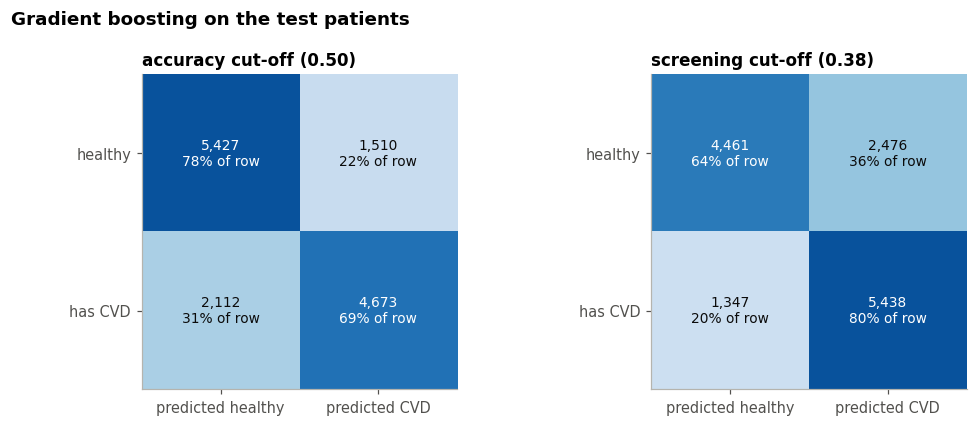

,accuracy,sensitivity,specificity
cut-off,,,
accuracy cut-off (0.50),73.6%,68.9%,78.2%
screening cut-off (0.38),72.1%,80.1%,64.3%


In [35]:
from sklearn.metrics import confusion_matrix

oof = out_of_fold(final, train)
cut_screen = screening_threshold(train["cardio"], oof, 0.80)
risk_test = test_scores[chosen]

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
summary = []
for ax, (label, cut) in zip(axes, [("accuracy cut-off (0.50)", 0.5), (f"screening cut-off ({cut_screen:.2f})", cut_screen)]):
    cm = confusion_matrix(y_test, risk_test >= cut)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}\n{v / cm[i].sum():.0%} of row", ha="center", va="center", fontsize=9,
                color="white" if v > cm.max() * 0.6 else INK)
    ax.set_xticks([0, 1], ["predicted healthy", "predicted CVD"])
    ax.set_yticks([0, 1], ["healthy", "has CVD"])
    ax.grid(False)
    ax.set_title(label)
    m = classification_metrics(y_test, risk_test, cut)
    summary.append({"cut-off": label, **m})
fig.suptitle(f"{chosen} on the test patients", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig9_confusion_matrices.png")
plt.show()
pd.DataFrame(summary).set_index("cut-off").drop(columns="auc").style.format("{:.1%}")

The screening cut-off, chosen on the training patients alone, detects 80.1% of the diseased test
patients: the target carries over to unseen patients. The price is specificity. At 0.50 the model
misses 2,112 of the 6,785 diseased test patients and flags 1,510 of the 6,937 healthy ones. At the
screening cut-off it misses 1,347 and flags 2,476. Which trade-off is right is not a statistical
question. It depends on what follows a positive result. For a cheap follow-up examination, the
screening cut-off is the sensible choice.

### 8.4 What drives the predictions

Two complementary views. **Grouped permutation importance** asks how much test AUC is lost when a
factor is scrambled across patients. Related features are scrambled together, so the four
blood-pressure features cannot cover for one another. **Partial dependence** asks how the average
predicted risk changes as one factor is varied for everyone.

In [36]:
# Features that carry the same information are permuted together: permuting systolic pressure alone
# would leave mean arterial pressure, pulse pressure and the stage to stand in for it.
FEATURE_GROUPS = {
    "blood pressure": ["ap_hi", "ap_lo", "pulse_pressure", "mean_arterial_pressure", "bp_stage"],
    "age": ["age_years"],
    "body size (height, weight, BMI)": ["height", "weight", "bmi"],
    "cholesterol": ["cholesterol"],
    "glucose": ["gluc"],
    "physical activity": ["active"],
    "smoking": ["smoke"],
    "alcohol": ["alco"],
    "sex": ["male"],
}


def grouped_permutation_importance(model, df: pd.DataFrame, groups: dict = FEATURE_GROUPS,
                                   n_repeats: int = 10, seed: int = SEED) -> pd.DataFrame:
    """Drop in AUC when each group of features is shuffled across patients (the same shuffle for every
    column of the group, so the group stays internally consistent but loses its link to the diagnosis)."""
    from sklearn.metrics import roc_auc_score

    rng = np.random.default_rng(seed)
    X, y = df[FEATURES], df[TARGET].to_numpy()
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = []
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            shuffled = X.copy()
            order = rng.permutation(len(X))
            shuffled[cols] = X[cols].to_numpy()[order]
            drops.append(base - roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
        rows.append({"features": name, "auc drop": np.mean(drops), "sd": np.std(drops, ddof=1)})
    return pd.DataFrame(rows).set_index("features").sort_values("auc drop", ascending=False)


def partial_dependence_curve(model, df: pd.DataFrame, feature: str, values) -> pd.Series:
    """Average predicted risk when every patient's `feature` is set to each value in turn, with the
    features derived from it recomputed, so the model never sees an impossible combination."""
    out = {}
    for v in values:
        d = df.copy()
        d[feature] = v
        if feature == "ap_hi":  # keep every diastolic reading below the systolic one it is paired with
            d["ap_lo"] = np.minimum(d["ap_lo"], v - 10)
        d = add_features(d.drop(columns=DERIVED_FEATURES))
        out[v] = model.predict_proba(d[FEATURES])[:, 1].mean()
    return pd.Series(out, name=feature)

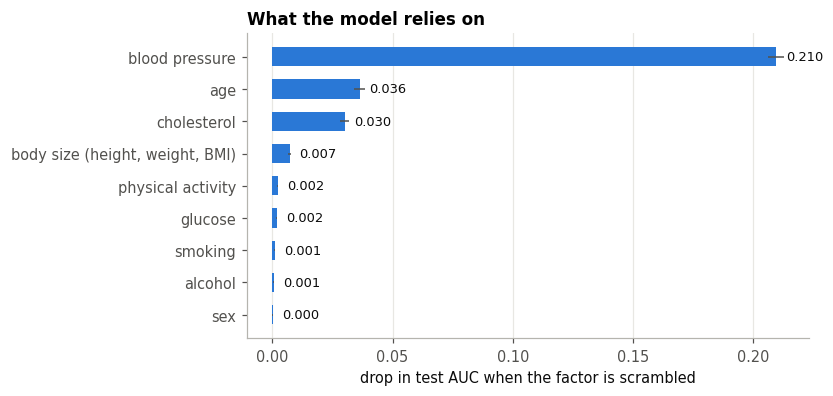

In [37]:
importance = grouped_permutation_importance(final, test)

fig, ax = plt.subplots(figsize=(6.6, 3.6))
order = importance.iloc[::-1]
ax.barh(order.index, order["auc drop"], xerr=order["sd"], color=NO_CVD, height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1})
for yi, v in enumerate(order["auc drop"]):
    ax.text(v + 0.004, yi, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
ax.set(xlabel="drop in test AUC when the factor is scrambled", title="What the model relies on")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "fig10_importance.png")
plt.show()

**Blood pressure dominates.** Scrambling the five blood-pressure features costs 0.21 AUC: without
them the AUC would fall from 0.80 to about 0.59. Age (0.036) and cholesterol (0.030) follow,
and body size adds a little (0.007). Glucose, the three lifestyle answers and sex together contribute
almost nothing. This matches the exploratory analysis in Section 5.

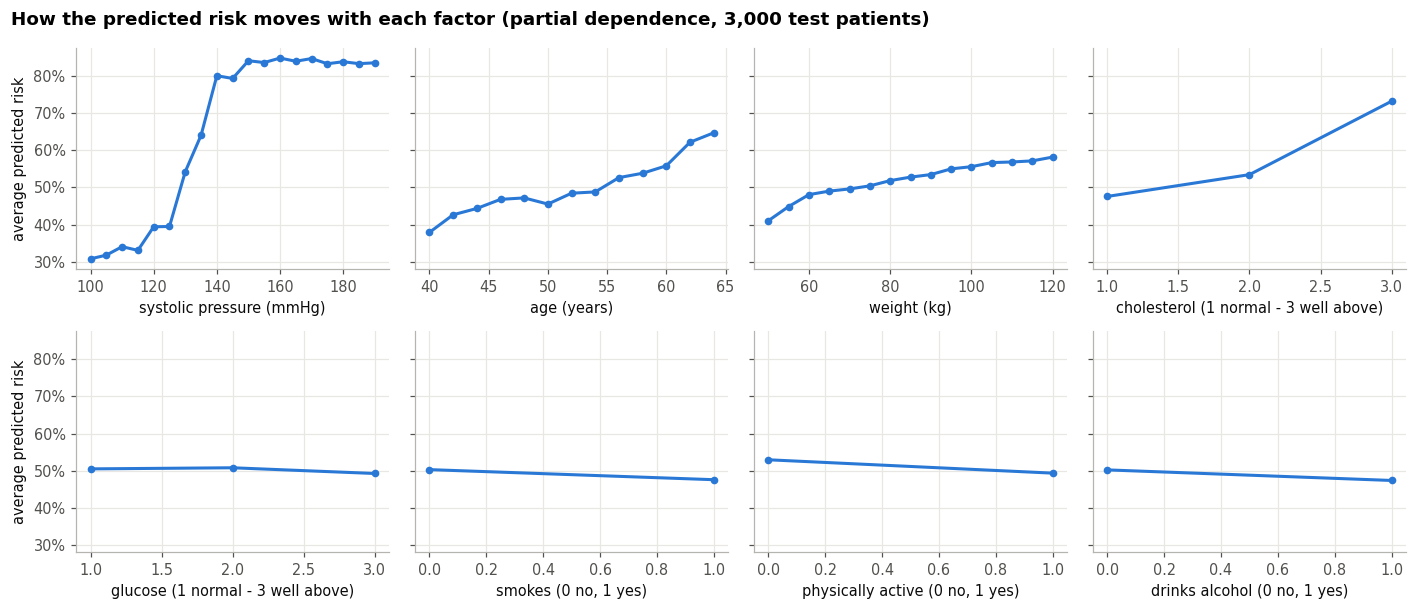

In [38]:
curves = [("ap_hi", range(100, 191, 5), "systolic pressure (mmHg)"),
          ("age_years", range(40, 66, 2), "age (years)"),
          ("weight", range(50, 121, 5), "weight (kg)"),
          ("cholesterol", [1, 2, 3], "cholesterol (1 normal - 3 well above)"),
          ("gluc", [1, 2, 3], "glucose (1 normal - 3 well above)"),
          ("smoke", [0, 1], "smokes (0 no, 1 yes)"),
          ("active", [0, 1], "physically active (0 no, 1 yes)"),
          ("alco", [0, 1], "drinks alcohol (0 no, 1 yes)")]
sample = test.sample(3000, random_state=SEED)

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
for ax, (feature, values, label) in zip(axes.flat, curves):
    pdc = partial_dependence_curve(final, sample, feature, list(values))
    ax.plot(pdc.index, pdc.values, "-o", color=NO_CVD, lw=2, ms=4)
    ax.set(xlabel=label)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
for ax in axes[:, 0]:
    ax.set_ylabel("average predicted risk")
fig.suptitle("How the predicted risk moves with each factor (partial dependence, 3,000 test patients)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "fig11_partial_dependence.png")
plt.show()

The partial-dependence curves show the *shape* of each effect, and why the trees beat logistic
regression:

- **Systolic pressure works like a switch, not a slope.** The average predicted risk stays around
  30-40% below 125 mmHg, climbs steeply between 125 and 150 mmHg, and then stays flat at about 84%.
  A logistic regression on raw pressure has to draw one straight line in log-odds through this
  S-shape. The trees follow it. The steep part sits exactly on the guideline's stage 1 and stage 2
  thresholds (130 and 140 mmHg).
- **Age, weight and cholesterol raise the risk steadily.** Age goes from about 38% at 40 to 65% at 64,
  and cholesterol "well above normal" adds about 25 percentage points.
- **Glucose, smoking and alcohol are flat or slightly *protective*.** This is the reverse-causation
  pattern from Section 5.2. The model has learned the data correctly, and the data reflects patients
  who changed their habits after diagnosis. **These curves describe associations in this dataset and
  must not be read as causal effects**: nothing here suggests that smoking is harmless.

### 8.5 A points score a doctor can use on paper

If the best model gains only a little over simpler ones, the most useful result might be a
transparent score. Here each factor is cut into clinical bands, a logistic regression is fitted on
the bands, and its coefficients are rounded to whole points (one point = 0.1 in log-odds). The total
then maps to a risk.

In [39]:
POINTS_BANDS = {
    "age_years": ([0, 45, 50, 55, 60, 200], ["<45", "45-49", "50-54", "55-59", "60+"]),
    "ap_hi": ([0, 120, 130, 140, 160, 400], ["<120", "120-129", "130-139", "140-159", "160+"]),
    "bmi": ([0, 25, 30, 35, 200], ["<25", "25-29.9", "30-34.9", "35+"]),
}
POINTS_LEVELS = {"cholesterol": {1: "normal", 2: "above normal", 3: "well above normal"},
                 "gluc": {1: "normal", 2: "above normal", 3: "well above normal"},
                 "smoke": {0: "no", 1: "yes"}, "alco": {0: "no", 1: "yes"}, "active": {0: "no", 1: "yes"}}
# The clinical scorecard: the four factors whose direction is medically sound (Section 8.5)
CLINICAL_FACTORS = ["age_years", "ap_hi", "bmi", "cholesterol"]
POINTS_LABELS = {"age_years": "Age (years)", "ap_hi": "Systolic pressure (mmHg)", "bmi": "BMI (kg/m²)",
                 "cholesterol": "Cholesterol", "gluc": "Glucose", "smoke": "Smokes", "alco": "Drinks alcohol",
                 "active": "Physically active"}


class PointsScore:
    """A paper scorecard: each factor's band earns whole points, and the total maps to a risk.

    Fitted as a logistic regression on banded factors (lowest band as reference). One point is worth
    `unit` in log-odds, so every coefficient is rounded to whole points. The total is then mapped back
    to a risk with a one-variable logistic regression on the training patients.
    """

    def __init__(self, unit: float = 0.1, factors: list[str] | None = None):
        self.unit = unit
        self.factors = factors or [*POINTS_BANDS, *POINTS_LEVELS]

    def _bands(self, df: pd.DataFrame) -> pd.DataFrame:
        cols = {}
        for col in self.factors:
            if col in POINTS_BANDS:
                edges, labels = POINTS_BANDS[col]
                cols[col] = pd.Categorical(pd.cut(df[col], edges, labels=labels, right=False), labels)
            else:
                levels = POINTS_LEVELS[col]
                cols[col] = pd.Categorical(df[col].map(levels), list(levels.values()))
        return pd.DataFrame(cols, index=df.index)

    def _design(self, df: pd.DataFrame) -> pd.DataFrame:
        return pd.get_dummies(self._bands(df), drop_first=True, dtype=float)

    def fit(self, df: pd.DataFrame, y):
        from sklearn.linear_model import LogisticRegression

        X = self._design(df)
        lr = LogisticRegression(C=1.0, max_iter=5000).fit(X, y)
        self.points_ = pd.Series(np.round(lr.coef_[0] / self.unit).astype(int), index=X.columns)
        self.calibration_ = LogisticRegression(C=1e6, max_iter=5000).fit(self.total(df).to_frame(), y)
        return self

    def total(self, df: pd.DataFrame) -> pd.Series:
        return (self._design(df)[self.points_.index] @ self.points_).rename("points")

    def predict_proba(self, df: pd.DataFrame) -> np.ndarray:
        return self.calibration_.predict_proba(self.total(df).to_frame())[:, 1]

    def table(self) -> pd.DataFrame:
        """The scorecard: every band of every factor with its points (reference bands score 0)."""
        rows = []
        for col in self.factors:
            labels = POINTS_BANDS[col][1] if col in POINTS_BANDS else list(POINTS_LEVELS[col].values())
            for label in labels:
                rows.append({"factor": POINTS_LABELS[col], "band": label,
                             "points": int(self.points_.get(f"{col}_{label}", 0))})
        return pd.DataFrame(rows)

    def risk_by_total(self, totals) -> pd.Series:
        totals = np.asarray(list(totals))
        return pd.Series(self.calibration_.predict_proba(pd.DataFrame({"points": totals}))[:, 1], index=totals)

In [40]:
points = PointsScore().fit(train, train["cardio"])
card = points.table()
card.set_index(["factor", "band"])

points
factor                   band                     
Age (years)              <45                     0
                         45-49                   4
                         50-54                   5
                         55-59                   8
                         60+                    11
Systolic pressure (mmHg) <120                    0
                         120-129                 5
                         130-139                13
                         140-159                25
                         160+                   27
BMI (kg/m²)              <25                     0
                         25-29.9                 2
                         30-34.9                 3
                         35+                     4
Cholesterol              normal                  0
                         above normal            3
                         well above normal      11
Glucose                  normal                  0
                         above normal            0
                         well above normal      -3
Smokes                   no                      0
                         yes                    -2
Drinks alcohol           no                      0
                         yes                    -2
Physically active        no                      0
                         yes                    -2

The scorecard reads like the model. Systolic pressure earns up to 27 points, age up to 11,
cholesterol up to 11, and BMI up to 4. The lifestyle answers and high glucose earn *negative* points,
for the reverse-causation reason above. No clinician could hand out a score that rewards smoking,
and these factors carry almost no information anyway (Section 8.4). So a **clinical version** keeps
only the four factors with a sound direction: age, systolic pressure, BMI and cholesterol.

points score on the test patients: AUC 0.795 (0.788-0.803), accuracy 72.5%, sensitivity 64.3%, specificity 80.6%
Gradient boosting minus points score: AUC +0.0090 (95% CI +0.0067 to +0.0112)


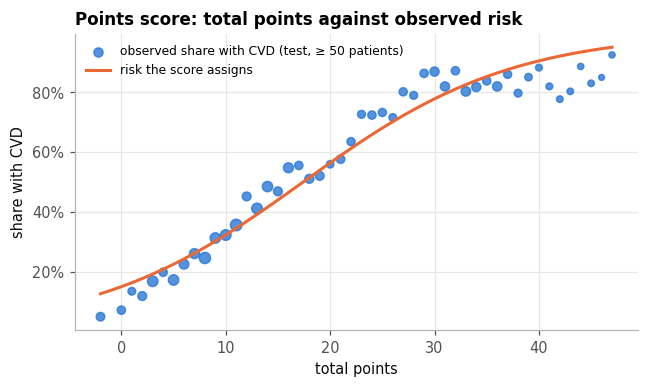

In [41]:
test_scores["Points score"] = points.predict_proba(test)
boot_points = bootstrap(y_test, {"Points score": test_scores["Points score"], chosen: test_scores[chosen]},
                               roc_auc_score)
m = classification_metrics(y_test, test_scores["Points score"], 0.5)
lo, hi = interval(boot_points["Points score"])
d_lo, d_hi = interval(boot_points[chosen] - boot_points["Points score"])
print(f"points score on the test patients: AUC {m['auc']:.3f} ({lo:.3f}-{hi:.3f}), accuracy {m['accuracy']:.1%}, "
      f"sensitivity {m['sensitivity']:.1%}, specificity {m['specificity']:.1%}")
print(f"{chosen} minus points score: AUC {roc_auc_score(y_test, test_scores[chosen]) - m['auc']:+.4f} "
      f"(95% CI {d_lo:+.4f} to {d_hi:+.4f})")

totals = points.total(test)
observed = test.groupby(totals)["cardio"].agg(["mean", "size"])
observed = observed[observed["size"] >= 50]
fig, ax = plt.subplots(figsize=(6.6, 3.5))
ax.scatter(observed.index, observed["mean"], s=np.sqrt(observed["size"]) * 2, color=NO_CVD, alpha=0.8,
           label="observed share with CVD (test, ≥ 50 patients)")
grid = np.arange(observed.index.min(), observed.index.max() + 1)
ax.plot(grid, points.risk_by_total(grid), color=CVD, lw=2, label="risk the score assigns")
ax.set(xlabel="total points", ylabel="share with CVD", title="Points score: total points against observed risk")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper left", fontsize=8)
fig.savefig(FIGURES / "fig12_points_score.png")
plt.show()

In [42]:
clinical = PointsScore(factors=CLINICAL_FACTORS).fit(train, train["cardio"])
test_scores["Points score (clinical, 4 factors)"] = clinical.predict_proba(test)
for name in ["Points score", "Points score (clinical, 4 factors)", "Logistic regression", chosen]:
    m = classification_metrics(y_test, test_scores[name], 0.5)
    print(f"{name:<38} AUC {m['auc']:.3f}   accuracy {m['accuracy']:.1%}")
clinical.table().set_index(["factor", "band"]).T

Points score                           AUC 0.795   accuracy 72.5%
Points score (clinical, 4 factors)     AUC 0.793   accuracy 72.3%
Logistic regression                    AUC 0.793   accuracy 72.6%
Gradient boosting                      AUC 0.804   accuracy 73.6%


factor Age (years)                       Systolic pressure (mmHg)          \
band           <45 45-49 50-54 55-59 60+                     <120 120-129   
points           0     4     5     8  11                        0       5   

factor                      BMI (kg/m²)                     Cholesterol  \
band   130-139 140-159 160+         <25 25-29.9 30-34.9 35+      normal   
points      13      25   27           0       2       3   4           0   

factor                                 
band   above normal well above normal  
points            3                 9

**Dropping the four questionable factors costs almost nothing.** The four-factor clinical scorecard
reaches an AUC of 0.793 and 72.3% accuracy: exactly logistic regression on all fifteen features, and
0.011 AUC below gradient boosting. A doctor with a pen can add up four numbers (age, systolic
pressure, BMI, cholesterol) and get within about one point of accuracy of the best machine-learning
model. This is in line with Rudin's argument that for tabular problems like this one, an
interpretable model is often nearly as accurate as a black box [9].

## 9. Reliability

Section 8 measured how well the model works. This section asks how far those numbers can be
trusted: how they depend on data handling choices (Q2), and whether the predicted risks hold up as
risks, for every kind of patient (Q3).

### 9.1 Does the cleaning strategy matter?

The final gradient-boosting setting and the logistic regression are trained three times: on the raw
training data, on the `drop` training data and on the `repair` training data. All six models are
scored on the same test patients (those whose records pass every check), so only the training data
differs.

The reliability checks of this section: the cleaning-strategy comparison, a minimal SMOTE, the three
deliberate mistakes, subgroup metrics and predictive value at other prevalences.

In [43]:
def strategy_comparison(estimators: dict, path: Path | str = DATA) -> pd.DataFrame:
    """Each estimator trained on each cleaning strategy's training patients and scored on the common
    test patients (those whose records pass every check), so only the training data differs."""
    from sklearn.base import clone
    from sklearn.metrics import roc_auc_score

    common = set(train_test("drop", path)[1]["id"])
    rows = []
    for strategy in STRATEGIES:
        tr, te = train_test(strategy, path)
        te = te[te["id"].isin(common)]
        for name, est in estimators.items():
            model = clone(est).fit(tr[FEATURES], tr[TARGET])
            risk = model.predict_proba(te[FEATURES])[:, 1]
            rows.append({"model": name, "strategy": strategy, "training patients": len(tr),
                         "test AUC": roc_auc_score(te[TARGET], risk),
                         "test accuracy": ((risk >= 0.5) == te[TARGET]).mean()})
    return pd.DataFrame(rows)


def smote(X: np.ndarray, y: np.ndarray, n_new: int, k: int = 5, seed: int = SEED):
    """SMOTE: new patients interpolated between a patient and one of its k nearest neighbours of the
    same class, n_new per class. Written out here because the leakage experiment needs nothing more."""
    from sklearn.neighbors import NearestNeighbors

    rng = np.random.default_rng(seed)
    new_X, new_y = [], []
    for c in np.unique(y):
        Xc = X[y == c]
        _, nbrs = NearestNeighbors(n_neighbors=k + 1).fit(Xc).kneighbors(Xc)
        i = rng.integers(0, len(Xc), n_new)
        j = nbrs[i, rng.integers(1, k + 1, n_new)]
        lam = rng.random((n_new, 1))
        new_X.append(Xc[i] + lam * (Xc[j] - Xc[i]))
        new_y.append(np.full(n_new, c))
    return np.vstack(new_X), np.concatenate(new_y)


def leakage_experiments(train: pd.DataFrame, test: pd.DataFrame, correct_accuracy: float,
                        seed: int = SEED) -> pd.DataFrame:
    """Accuracy 'reported' by pipelines that make mistakes common in published work on this kind of
    data, next to the correct pipeline. Each mistake lets the evaluation see what it should not."""
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    rows = [{"pipeline": "Correct: model chosen by cross-validation, scored once on unseen patients",
             "model": "gradient boosting", "reported accuracy": correct_accuracy}]

    # 1. scoring the model on the patients it was trained on
    # 50 fully grown trees: enough to show the effect, and they stay well inside the 4 GB container
    forest = RandomForestClassifier(n_estimators=50, min_samples_leaf=1, random_state=seed, n_jobs=N_JOBS)
    forest.fit(train[FEATURES], train[TARGET])
    rows.append({"pipeline": "Mistake 1: accuracy measured on the training patients",
                 "model": "random forest (fully grown trees)",
                 "reported accuracy": forest.score(train[FEATURES], train[TARGET])})
    rows.append({"pipeline": "  (the same forest on unseen patients)", "model": "random forest (fully grown trees)",
                 "reported accuracy": forest.score(test[FEATURES], test[TARGET])})

    # 2. oversampling (SMOTE) the whole dataset, then splitting it
    everything = pd.concat([train, test])
    X, y = everything[FEATURES].to_numpy(float), everything[TARGET].to_numpy()
    sx, sy = smote(X, y, n_new=len(everything), seed=seed)      # triples the data, as some papers do
    Xa, ya = np.vstack([X, sx]), np.concatenate([y, sy])
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=TEST_SIZE, stratify=ya, random_state=seed)
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
    for label, model in [("k-nearest neighbours (k = 1)", knn), ("random forest (fully grown trees)", forest)]:
        model.fit(Xtr, ytr)
        rows.append({"pipeline": "Mistake 2: SMOTE oversampling before the train/test split", "model": label,
                     "reported accuracy": model.score(Xte, yte)})
    # the same models with SMOTE applied correctly: on the training patients only
    tx, ty = train[FEATURES].to_numpy(float), train[TARGET].to_numpy()
    sx, sy = smote(tx, ty, n_new=len(train), seed=seed)
    for label, model in [("k-nearest neighbours (k = 1)", knn), ("random forest (fully grown trees)", forest)]:
        model.fit(np.vstack([tx, sx]), np.concatenate([ty, sy]))
        rows.append({"pipeline": "  (SMOTE on the training patients only, scored on unseen patients)", "model": label,
                     "reported accuracy": model.score(test[FEATURES].to_numpy(float), test[TARGET])})

    # 3. trying many random splits and reporting the luckiest
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
    accs = []
    for s in range(50):
        a, b = train_test_split(everything, test_size=TEST_SIZE, stratify=everything[TARGET], random_state=s)
        accs.append(lr.fit(a[FEATURES], a[TARGET]).score(b[FEATURES], b[TARGET]))
    rows.append({"pipeline": "Mistake 3: best of 50 random train/test splits", "model": "logistic regression",
                 "reported accuracy": max(accs)})
    rows.append({"pipeline": "  (the median split)", "model": "logistic regression",
                 "reported accuracy": float(np.median(accs))})
    return pd.DataFrame(rows)


def subgroup_table(df: pd.DataFrame, risk, threshold: float = 0.5) -> pd.DataFrame:
    """AUC, sensitivity, specificity and mean predicted vs observed risk, by sex and by age band."""
    from sklearn.metrics import roc_auc_score

    d = df.assign(risk=np.asarray(risk))
    groups = {
        "women": d["male"] == 0, "men": d["male"] == 1,
        "age < 50": d["age_years"] < 50, "age 50-59": d["age_years"].between(50, 60, inclusive="left"),
        "age 60+": d["age_years"] >= 60, "everyone": pd.Series(True, index=d.index),
    }
    rows = []
    for name, mask in groups.items():
        g = d[mask]
        m = classification_metrics(g[TARGET], g["risk"], threshold)
        rows.append({"group": name, "patients": len(g), "share with CVD": g[TARGET].mean(),
                     "mean predicted risk": g["risk"].mean(), "AUC": m["auc"],
                     "sensitivity": m["sensitivity"], "specificity": m["specificity"]})
    return pd.DataFrame(rows).set_index("group")


def ppv_at_prevalence(sensitivity: float, specificity: float, prevalence: float) -> float:
    """Share of flagged patients who really have CVD, in a population with the given prevalence."""
    tp = sensitivity * prevalence
    fp = (1 - specificity) * (1 - prevalence)
    return tp / (tp + fp)

In [44]:
strategies = strategy_comparison({"Gradient boosting": final, "Logistic regression": searches["Logistic regression"].best_estimator_})
(strategies.pivot(index="strategy", columns="model", values=["test AUC", "test accuracy"])
 .reindex(list(STRATEGIES)).style.format("{:.4f}"))

The answer depends on the model, exactly as Section 4.3 predicted:

- **Gradient boosting does not care.** Its test AUC is 0.804 whether it is trained on the raw,
  dropped or repaired data. Trees split on the order of values, so a pressure of 16,020 mmHg simply
  lands in the top branch with every other high reading.
- **Logistic regression is hurt by the raw data.** Its AUC falls from 0.793 to 0.776. A handful of
  absurd values pull its single straight-line coefficient for blood pressure towards zero, which
  drowns out the strongest predictor.
- **Repairing and dropping give the same result.** The 1,257 repaired records are under 2% of the
  data, too few to change what the model learns. Repair keeps more patients, but its value lies in
  not discarding real people rather than in accuracy.

The practical lesson: cleaning is essential for linear models and for any analysis that reads
coefficients or correlations (Section 4.3), even when a tree model would have survived without it.

### 9.2 How mistakes inflate reported accuracy

Papers on this dataset report accuracies from 73% [5] to 94.5% [7]. This experiment reproduces three
mistakes common in published machine-learning work on medical data and measures the accuracy each
one would let a study report. Each mistake is shown next to the honest figure for the same model.
These pipelines are wrong on purpose, and none of them feeds into the model chosen above. Which
mistakes, if any, particular papers made cannot be known from here.

In [45]:
t0 = time.time()
correct_acc = classification_metrics(y_test, test_scores[chosen], 0.5)["accuracy"]
leakage = leakage_experiments(train, test, correct_acc)
print(f"leakage experiments: {time.time() - t0:.0f} s")
leakage.style.format({"reported accuracy": "{:.1%}"}).hide(axis="index")

leakage experiments: 138 s


pipeline,model,reported accuracy
"Correct: model chosen by cross-validation, scored once on unseen patients",gradient boosting,73.6%
Mistake 1: accuracy measured on the training patients,random forest (fully grown trees),99.9%
(the same forest on unseen patients),random forest (fully grown trees),71.0%
Mistake 2: SMOTE oversampling before the train/test split,k-nearest neighbours (k = 1),85.3%
Mistake 2: SMOTE oversampling before the train/test split,random forest (fully grown trees),86.7%
"(SMOTE on the training patients only, scored on unseen patients)",k-nearest neighbours (k = 1),64.0%
"(SMOTE on the training patients only, scored on unseen patients)",random forest (fully grown trees),70.5%
Mistake 3: best of 50 random train/test splits,logistic regression,73.4%
(the median split),logistic regression,72.8%


The same data can "report" anything from 64% to 99.9% accuracy, depending on how the evaluation is
set up:

1. **Accuracy measured on the training patients.** A forest of fully grown trees memorises its
   training patients and scores 99.9% on them, against 71.0% on patients it has never seen. Any
   figure that does not come from held-out patients says nothing about the model.
2. **SMOTE before the split** [10]. Synthetic patients are interpolated between real neighbours,
   so after a random split most test patients have a near-twin in the training set. A one-nearest-
   neighbour classifier then "reaches" 85.3% and the forest 86.7%: inflated by 16-21 points. These
   accuracies are close to those reported in [6]. Applied correctly, to the training patients only,
   SMOTE does nothing useful here (the classes are already balanced) and both models fall to 64-71%.
   The same mistake explained a published 99% accuracy on another cardiovascular dataset; once it was
   corrected, accuracy fell to 77% [11].
3. **Trying many random splits and reporting the best one.** This is the mildest mistake: the best
   of 50 splits is 73.4%, against 72.8% for the median split. With 14,000 test patients the luck of
   the split is worth less than one point. It matters far more in small datasets.

None of this shows what the authors of [6] or [7] actually did; their papers would have to be
reproduced to know. What it does show is that **an accuracy far above 74% on this dataset should be
read as a sign of leakage until the pipeline proves otherwise**: the learning curve in Section 7.4
gives no reason to expect a model to gain 15 or 20 points.

### 9.3 Can the predicted risks be taken at face value?

A risk of 70% should mean that about 70 of 100 such patients have CVD. The calibration curve groups
the test patients by predicted risk and compares each group's average prediction with the share who
actually have CVD. The Brier score (the mean squared error of the risks) sums up both calibration
and discrimination: lower is better, and always predicting 50% scores 0.25.

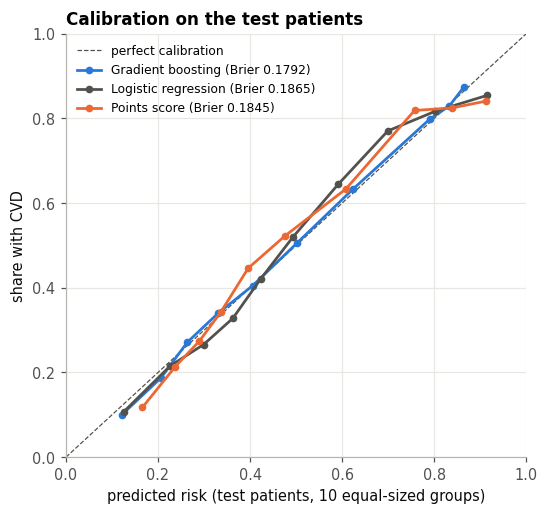

In [46]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.plot([0, 1], [0, 1], ls="--", lw=0.8, color=MUTED, label="perfect calibration")
for name, colour in [(chosen, NO_CVD), ("Logistic regression", MUTED), ("Points score", CVD)]:
    observed, predicted = calibration_curve(y_test, test_scores[name], n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_test, test_scores[name])
    ax.plot(predicted, observed, "-o", color=colour, lw=1.8, ms=4, label=f"{name} (Brier {brier:.4f})")
ax.set(xlabel="predicted risk (test patients, 10 equal-sized groups)", ylabel="share with CVD",
       title="Calibration on the test patients", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=8)
fig.savefig(FIGURES / "fig13_calibration.png")
plt.show()

**Gradient boosting's risks can be read as risks.** Its ten points lie on the diagonal: patients
given about 20% have CVD about 20% of the time, and patients given 80% about 80% of the time. It also
has the lowest Brier score (0.179). Logistic regression bends around the diagonal: it overstates low
risks and understates the risk around 60-70%, the S-shaped error of a straight line forced through
the switch-like effect of blood pressure (Section 8.4). The points score is close to calibrated, with
a small excess of observed cases in the middle range.

### 9.4 Does the model work equally well for everyone?

In [47]:
subgroups = subgroup_table(test, test_scores[chosen])
subgroups.style.format({"patients": "{:,}", "share with CVD": "{:.1%}", "mean predicted risk": "{:.1%}",
                        "AUC": "{:.3f}", "sensitivity": "{:.1%}", "specificity": "{:.1%}"})

,patients,share with CVD,mean predicted risk,AUC,sensitivity,specificity
group,,,,,,
women,"8,858",49.2%,48.7%,0.803,68.0%,78.6%
men,"4,864",49.9%,50.7%,0.808,70.4%,77.6%
age < 50,"4,361",36.8%,36.3%,0.835,59.0%,91.4%
age 50-59,"6,900",50.8%,51.6%,0.768,64.2%,77.7%
age 60+,"2,461",67.9%,66.5%,0.718,88.1%,34.7%
everyone,"13,722",49.4%,49.4%,0.804,68.9%,78.2%


- **Women and men are served equally.** Their AUCs (0.803 and 0.808) and error rates are close, and
  in both groups the mean predicted risk matches the observed share within 1 point.
- **Age is different.** Discrimination falls with age, from an AUC of 0.835 below 50 to 0.718 at 60
  and over. Among older patients most have high blood pressure and most have CVD, so the main signal
  separates them less well. The risks remain calibrated in every age group (mean predicted vs
  observed within 1.5 points). But at the 0.5 cut-off the model flags 88% of diseased patients over 60
  while clearing only 35% of the healthy ones; below 50 it is the reverse (59% and 91%). A single
  cut-off does not suit every age. A deployed tool could use age-specific cut-offs, or report the risk
  itself and leave the threshold to the clinician.

### 9.5 What the numbers mean outside this dataset

Half the patients in this dataset have CVD. In the population that attends a routine check-up the
share is much lower, and this changes what a positive prediction means. Sensitivity and
specificity describe the model and carry over. The **positive predictive value**, the chance that a
flagged patient really has CVD, depends on how common the disease is:

In [48]:
m_acc = classification_metrics(y_test, test_scores[chosen], 0.5)
m_scr = classification_metrics(y_test, test_scores[chosen], cut_screen)
ppv = pd.DataFrame({f"{label} (sens {m['sensitivity']:.0%}, spec {m['specificity']:.0%})":
                    {f"{p:.0%}": ppv_at_prevalence(m["sensitivity"], m["specificity"], p)
                     for p in (0.5, 0.3, 0.2, 0.1, 0.05)}
                    for label, m in [("accuracy cut-off", m_acc), ("screening cut-off", m_scr)]})
ppv.index.name = "share of patients with CVD"
ppv.style.format("{:.0%}")

,"accuracy cut-off (sens 69%, spec 78%)","screening cut-off (sens 80%, spec 64%)"
share of patients with CVD,,
50%,76%,69%
30%,58%,49%
20%,44%,36%
10%,26%,20%
5%,14%,11%


In this dataset 76% of the patients the model flags really have CVD. In a check-up population where
one patient in five has CVD, the same model, with the same sensitivity and specificity, would be right
about only 44% of the patients it flags (36% at the screening cut-off). The model is still useful
there, because it concentrates the disease: 44% is more than twice the 20% base rate. But its verdict
has to be read as "worth a closer look", not as a diagnosis. And before its *risks* could be used in
such a population, it would have to be recalibrated to that population's prevalence.

## 10. Using the model

The project's goal was a model that checks a patient for cardiovascular disease. The code below
turns the chosen model into that check. It saves the model with its two cut-offs and the clinical
scorecard to `outputs/model.joblib`. It also checks a new examination with the same plausibility
rules as the data, so an impossible reading is rejected instead of scored, and then reports the risk,
the verdict and the points.

In [49]:
MODEL_FILE = OUTPUTS / "model.joblib"
# The setting Section 7 selected for gradient boosting by cross-validation (the report checks that
# its own search still agrees with this before saving the model)
FINAL_PARAMS = {"learning_rate": 0.01, "max_leaf_nodes": 15, "min_samples_leaf": 50}
SCREENING_SENSITIVITY = 0.80


def final_estimator():
    from sklearn.ensemble import HistGradientBoostingClassifier
    return HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED, **FINAL_PARAMS)


def build_final(train: pd.DataFrame, model=None) -> dict:
    """Everything needed to assess a new patient: the fitted model, the two cut-offs and the scorecard."""
    model = model if model is not None else final_estimator().fit(train[FEATURES], train[TARGET])
    oof = out_of_fold(model, train)
    return {"model": model, "accuracy_cutoff": 0.5,
            "screening_cutoff": screening_threshold(train[TARGET], oof, SCREENING_SENSITIVITY),
            "points": PointsScore(factors=CLINICAL_FACTORS).fit(train, train[TARGET]), "features": FEATURES}


def save_final(bundle: dict, path: Path = MODEL_FILE) -> Path:
    import joblib
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(bundle, path)
    return path


def load_final(path: Path = MODEL_FILE) -> dict:
    import joblib
    if not Path(path).exists():
        raise FileNotFoundError(f"{path} not found: fit and save the final model first (build_final, save_final)")
    return joblib.load(path)


def patient(age: float, sex: str, height: float, weight: float, systolic: float, diastolic: float,
            cholesterol: int = 1, glucose: int = 1, smoke: int = 0, alcohol: int = 0, active: int = 1) -> pd.DataFrame:
    """One patient's examination as a model-ready row, after the same plausibility checks as the data.

    age in years; sex 'female' or 'male'; height cm; weight kg; blood pressure mmHg; cholesterol and
    glucose 1 normal, 2 above normal, 3 well above normal; smoke, alcohol, active 0 or 1.
    """
    if sex not in ("female", "male"):
        raise ValueError("sex must be 'female' or 'male'")
    for name, value, allowed in [("cholesterol", cholesterol, (1, 2, 3)), ("glucose", glucose, (1, 2, 3)),
                                 ("smoke", smoke, (0, 1)), ("alcohol", alcohol, (0, 1)), ("active", active, (0, 1))]:
        if value not in allowed:
            raise ValueError(f"{name} must be one of {allowed}, not {value!r}")
    raw = pd.DataFrame([{"id": 0, "age": age * 365.25, "gender": 2 if sex == "male" else 1, "height": height,
                         "weight": weight, "ap_hi": systolic, "ap_lo": diastolic, "cholesterol": cholesterol,
                         "gluc": glucose, "smoke": smoke, "alco": alcohol, "active": active, TARGET: 0}])
    failed = audit(raw).iloc[0]
    if failed.any():
        raise ValueError("implausible examination values: " + ", ".join(failed.index[failed]))
    return add_features(prepare(raw))


def assess(bundle: dict, row: pd.DataFrame) -> dict:
    """Predicted risk, the verdict at both cut-offs, and the scorecard's points for one patient."""
    risk = float(bundle["model"].predict_proba(row[bundle["features"]])[:, 1][0])
    points = bundle["points"]
    design = points._design(row)[points.points_.index].iloc[0]
    earned = points.points_[design == 1]
    readable = {}
    for column, value in earned.items():
        factor = next(f for f in points.factors if column.startswith(f + "_"))
        readable[f"{POINTS_LABELS[factor]}: {column[len(factor) + 1:]}"] = int(value)
    return {"risk": risk,
            "verdict": "cardiovascular disease likely" if risk >= bundle["accuracy_cutoff"] else "cardiovascular disease unlikely",
            "screening": "refer for examination" if risk >= bundle["screening_cutoff"] else "no referral",
            "screening_cutoff": bundle["screening_cutoff"],
            "points": int(earned.sum()), "points_risk": float(points.predict_proba(row)[0]),
            "points_breakdown": {k: v for k, v in readable.items() if v != 0}}

In [50]:
# the setting fixed in FINAL_PARAMS must be the one this report selected
selected = {k: v for k, v in final.get_params().items() if k in FINAL_PARAMS}
assert selected == FINAL_PARAMS, (selected, FINAL_PARAMS)

bundle = build_final(train, model=final)
print("saved:", save_final(bundle).relative_to(ROOT))
print(f"screening cut-off: {bundle['screening_cutoff']:.3f}")

saved: outputs/model.joblib
screening cut-off: 0.382


Two invented examination records show the output:

In [51]:
examples = {
    "62-year-old man, 165/100 mmHg, BMI 33, cholesterol well above normal":
        dict(age=62, sex="male", height=172, weight=98, systolic=165, diastolic=100, cholesterol=3),
    "44-year-old woman, 115/75 mmHg, BMI 22, all results normal":
        dict(age=44, sex="female", height=165, weight=60, systolic=115, diastolic=75),
    "55-year-old woman, 130/85 mmHg, BMI 27, cholesterol above normal":
        dict(age=55, sex="female", height=160, weight=69, systolic=130, diastolic=85, cholesterol=2),
}
rows = []
for label, values in examples.items():
    r = assess(bundle, patient(**values))
    rows.append({"patient": label, "predicted risk": r["risk"], "verdict": r["verdict"],
                 "screening": r["screening"], "points": r["points"], "risk from points": r["points_risk"]})
pd.DataFrame(rows).set_index("patient").style.format({"predicted risk": "{:.0%}", "risk from points": "{:.0%}"})

,predicted risk,verdict,screening,points,risk from points
patient,,,,,
"62-year-old man, 165/100 mmHg, BMI 33, cholesterol well above normal",87%,cardiovascular disease likely,refer for examination,50,95%
"44-year-old woman, 115/75 mmHg, BMI 22, all results normal",14%,cardiovascular disease unlikely,no referral,0,13%
"55-year-old woman, 130/85 mmHg, BMI 27, cholesterol above normal",59%,cardiovascular disease likely,refer for examination,26,66%


The three invented patients get the answers a clinician would expect. The 62-year-old man with
stage 2 hypertension, obesity and high cholesterol is at 87%. The young woman with normal results is
at 14%. The 55-year-old woman in between is at 59%, so she is referred at either cut-off. The saved
tool uses the four-factor clinical scorecard (Section 8.5), and it ranks the three patients in the
same order as the model.

In [52]:
try:
    patient(age=50, sex="male", height=175, weight=80, systolic=1400, diastolic=90)
except ValueError as e:
    print("rejected:", e)

rejected: implausible examination values: ap_hi out of range


A new patient needs only the saved file: `assess(load_final(), patient(...))` gives the same
answer in any later session.

## 11. Conclusion

**Objective met.** A gradient-boosting model detects cardiovascular disease from the eleven values of
a routine examination. On 13,722 patients it never saw, it reaches an AUC of 0.804 (95% CI
0.797-0.811) and 73.6% accuracy. Its risks are well calibrated, and it works equally well for women
and men. Section 10 packages it as a check of a new examination that rejects impossible values
and returns a risk, a verdict and a points breakdown.

**Q1. What machine learning adds over what a doctor already has: something real, but small.**

- **Over the guideline rule.** The model beats systolic pressure ≥ 130 mmHg by 2.3 points of
  accuracy. At the rule's specificity, it detects 301 more of 6,785 diseased patients.
- **Between the models.** The three flexible models are tied, and logistic regression is only 0.012
  AUC behind.
- **The scorecard.** A four-factor paper score comes within 0.011 AUC of the best model.
- **Why the gain is small.** The learning curve is flat, so the ceiling of about 0.80 AUC (73-74%
  accuracy) is set by what the examination records, not by the algorithm or the amount of data.
- **The Framingham score.** As published, it ranks these patients worse than blood pressure alone,
  and it only becomes competitive once refitted to them.

**Q2. Data handling decides more than the algorithm does.**

- **Cleaning.** Fewer than 2% of records hide the strongest predictor from any linear analysis, and
  cost logistic regression 0.017 AUC. Tree models survive the dirty data, and repairing the records
  is as good as dropping them.
- **Leakage.** Common pipeline mistakes turn the same data into reported accuracies of 85-100%. Claims
  far above 74% on this dataset should be treated as signs of leakage until shown otherwise.

**Q3. The predictions can be trusted, within limits.**

- **Calibration.** The risks are calibrated overall, for both sexes and in every age group.
- **What drives them.** The explanations are dominated by blood pressure, age and cholesterol, in the
  direction medicine expects.
- **Weak spots.** Discrimination is weaker in patients over 60. The lifestyle answers carry
  reverse-caused associations that must not be read as effects.

### Limitations

1. **Detection, not prediction.** Diagnosis and features come from the same examination. The model
   recognises existing disease. It cannot forecast who will develop CVD.
2. **Unknown provenance and outcome definition.** The dataset's source and the exact meaning of
   "cardiovascular disease" are undocumented. If the label includes diagnosed hypertension, part of
   blood pressure's predictive power is circular.
3. **Treatment is not recorded.** Medication lowers blood pressure and cholesterol in diagnosed
   patients, and diagnosis changes habits. Both weaken or reverse associations (Section 5.2), and
   neither can be corrected for here.
4. **A 50/50 sample.** Predictive values and absolute risks apply to this sample. Another population
   needs recalibration (Section 9.5).
5. **One dataset.** All results come from one source with one train/test split. The split is large
   and every estimate carries a confidence interval, but there is no external validation.
6. **Coarse measurements.** Cholesterol and glucose come in three categories, and diabetes had to be
   approximated for the Framingham score.

The next step for this model would be validation on data from a known clinical source, with
recorded treatment and, ideally, outcomes followed over time. Those are what would turn a detector of
existing disease into a tool for prevention.

## References

1. World Health Organization. *Cardiovascular diseases (CVDs)*, fact sheet.
2. S. Ulianova. *Cardiovascular Disease dataset*. Kaggle, 2019.
3. P. K. Whelton et al. 2017 ACC/AHA guideline for the prevention, detection, evaluation, and
   management of high blood pressure in adults. *Hypertension*, 71(6):e13-e115, 2018.
4. R. B. D'Agostino Sr et al. General cardiovascular risk profile for use in primary care: the
   Framingham Heart Study. *Circulation*, 117(6):743-753, 2008.
5. R. S. Ramesh, R. T. S. Udupa, Monisha J and Kushi K. K. S. Cardiovascular disease prediction using
   machine learning: a comparative analysis. arXiv:2507.21898, 2025.
6. D. Y. Omkari and K. Shaik. An integrated two-layered voting (TLV) framework for coronary artery
   disease prediction using machine learning classifiers. *IEEE Access*, 2024.
   doi:10.1109/ACCESS.2024.3389707.
7. A. R. Zafar et al. Cardiovascular diagnostic detection using multilayer perceptron approach.
   *Systems and Soft Computing*, 2026. doi:10.1016/j.sasc.2026.200490.
8. A. G. Shaper, G. Wannamethee and M. Walker. Alcohol and mortality in British men: explaining the
   U-shaped curve. *The Lancet*, 2(8623):1267-1273, 1988.
9. C. Rudin. Stop explaining black box machine learning models for high stakes decisions and use
   interpretable models instead. *Nature Machine Intelligence*, 1:206-215, 2019.
10. N. V. Chawla, K. W. Bowyer, L. O. Hall and W. P. Kegelmeyer. SMOTE: synthetic minority
    over-sampling technique. *Journal of Artificial Intelligence Research*, 16:321-357, 2002.
11. Eltawil et al. Comment on Iacobescu et al. "Evaluating binary classifiers for cardiovascular
    disease prediction: enhancing early diagnostic capabilities". *Journal of Cardiovascular
    Development and Disease*, 13(1):46, 2026. doi:10.3390/jcdd13010046.
12. F. Pedregosa et al. Scikit-learn: machine learning in Python. *Journal of Machine Learning
    Research*, 12:2825-2830, 2011.